**После удаления неправильной строки из датасета**

In [64]:
from catboost import CatBoostClassifier
from catboost import Pool
from sklearn.model_selection import GroupKFold, ParameterGrid
from sklearn.metrics import f1_score, classification_report, confusion_matrix

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

In [65]:
import catboost

In [66]:
df = pd.read_csv("Data/data_kern_ratios_06_10.csv")

In [67]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3027 entries, 0 to 3026
Data columns (total 54 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Mg                        3027 non-null   float64
 1   Al                        3027 non-null   float64
 2   Si                        3027 non-null   float64
 3   P                         3027 non-null   float64
 4   S                         3027 non-null   float64
 5   K                         3027 non-null   float64
 6   Ca                        3027 non-null   float64
 7   Ti                        3027 non-null   float64
 8   Mn                        3027 non-null   float64
 9   Fe                        3027 non-null   float64
 10  Ni                        3027 non-null   float64
 11  Cu                        3027 non-null   float64
 12  Zn                        3027 non-null   float64
 13  Se                        3027 non-null   float64
 14  Rb      

In [68]:
df['Strat'].value_counts().sort_index()

Strat
0     448
1     156
2     182
3     267
4     232
5     133
6     131
7     194
8     365
9     469
10    267
11    183
Name: count, dtype: int64

**Кросс-валидация по скважинам с фиксированным набором гиперпараметров по относительным параметрам на основе элементов и соотношений на новом датасете 05.10 с новой разметкой**

In [69]:
features = [
    'Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
    'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo',
    '(Ca+Mg)/(Al+Si)',
    'Sr/Ca',
    'Mn/Ca',
    '(Al+K)/(Ca+Mg+Si)',
    'Zr/Al',
    'Zr/Si',
    'K/Al',
    'Ti/(Zr+Ti)',
    'Si/Al',
    'P/Al',
    'Ni/Fe',
    'Ni/(Si+Ca+Mg)',
    'S/(Rb+Zr)',
    'Mo/Al',
    'Mo/(Mn+Mo)',
    'Mn/Al',
    'Fe/S',
    'Ni/S',
    'Fe/(Ca+Mg+Al)',
    'Ti/(Si+Ca+Mg)',
    'Fe/(Mn+Fe)',
    '(Al+K+Ti)/Si',
    '(Al+K+Ti)/S',
    '(Ti+Rb+Zr)/S',
    'S/Ti',
    'Ni/Al',
    'Zn/Al',
    'Se/Si',
    '(Ca+Mg)/Al',
    'Se/Ti',
    '(10*Rb+Ti+10*Zr)/Se*1000'
]

**Расчет скользящих градиентов Δxi = xi - xi-1 по каждой скважине (сортировка по Depth)**

In [70]:
# Сортировка df по скважине и глубине
df_sorted = df.sort_values(['Well', 'Depth']).reset_index(drop=True)

# Для каждого признака разность с предыдущей пробой в той же скважине
gradient_features = []
for col in features:
    grad_col = f'dΔ_{col}'
    df_sorted[grad_col] = df_sorted.groupby('Well')[col].diff()
    gradient_features.append(grad_col)

# Исходный порядок
df = df_sorted

print(f"Добавлено градиентных признаков: {len(gradient_features)}")

Добавлено градиентных признаков: 49


In [71]:
print(df.columns.tolist())

['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo', 'Well', 'Sample', 'Depth', 'Stratigraphy', 'Strat', '(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)', 'Zr/Al', 'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)', 'Si/Al', 'P/Al', 'Ni/Fe', 'Ni/(Si+Ca+Mg)', 'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al', 'Fe/S', 'Ni/S', 'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)', '(Al+K+Ti)/Si', '(Al+K+Ti)/S', '(Ti+Rb+Zr)/S', 'S/Ti', 'Ni/Al', 'Zn/Al', 'Se/Si', '(Ca+Mg)/Al', 'Se/Ti', '(10*Rb+Ti+10*Zr)/Se*1000', 'dΔ_Mg', 'dΔ_Al', 'dΔ_Si', 'dΔ_P', 'dΔ_S', 'dΔ_K', 'dΔ_Ca', 'dΔ_Ti', 'dΔ_Mn', 'dΔ_Fe', 'dΔ_Ni', 'dΔ_Cu', 'dΔ_Zn', 'dΔ_Se', 'dΔ_Rb', 'dΔ_Sr', 'dΔ_Zr', 'dΔ_Mo', 'dΔ_(Ca+Mg)/(Al+Si)', 'dΔ_Sr/Ca', 'dΔ_Mn/Ca', 'dΔ_(Al+K)/(Ca+Mg+Si)', 'dΔ_Zr/Al', 'dΔ_Zr/Si', 'dΔ_K/Al', 'dΔ_Ti/(Zr+Ti)', 'dΔ_Si/Al', 'dΔ_P/Al', 'dΔ_Ni/Fe', 'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_S/(Rb+Zr)', 'dΔ_Mo/Al', 'dΔ_Mo/(Mn+Mo)', 'dΔ_Mn/Al', 'dΔ_Fe/S', 'dΔ_Ni/S', 'dΔ_Fe/(Ca+Mg+Al)', 'dΔ_Ti/(Si+Ca+Mg)', 'dΔ_

In [72]:
features = ['dΔ_Mg', 'dΔ_Al', 'dΔ_Si', 'dΔ_P', 'dΔ_S', 'dΔ_K', 'dΔ_Ca', 'dΔ_Ti', 
            'dΔ_Mn', 'dΔ_Fe', 'dΔ_Ni', 'dΔ_Cu', 'dΔ_Zn', 'dΔ_Se', 'dΔ_Rb', 'dΔ_Sr', 
            'dΔ_Zr', 'dΔ_Mo', 'dΔ_(Ca+Mg)/(Al+Si)', 'dΔ_Sr/Ca', 'dΔ_Mn/Ca', 'dΔ_(Al+K)/(Ca+Mg+Si)', 
            'dΔ_Zr/Al', 'dΔ_Zr/Si', 'dΔ_K/Al', 'dΔ_Ti/(Zr+Ti)', 'dΔ_Si/Al', 'dΔ_P/Al', 'dΔ_Ni/Fe', 
            'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_S/(Rb+Zr)', 'dΔ_Mo/Al', 'dΔ_Mo/(Mn+Mo)', 'dΔ_Mn/Al', 'dΔ_Fe/S', 
            'dΔ_Ni/S', 'dΔ_Fe/(Ca+Mg+Al)', 'dΔ_Ti/(Si+Ca+Mg)', 'dΔ_Fe/(Mn+Fe)', 'dΔ_(Al+K+Ti)/Si', 
            'dΔ_(Al+K+Ti)/S', 'dΔ_(Ti+Rb+Zr)/S', 'dΔ_S/Ti', 'dΔ_Ni/Al', 'dΔ_Zn/Al', 'dΔ_Se/Si', 
            'dΔ_(Ca+Mg)/Al', 'dΔ_Se/Ti', 'dΔ_(10*Rb+Ti+10*Zr)/Se*1000'
]

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2380 проб, Val: 647 проб
F1 macro (train): 0.9965
F1 macro (val):   0.4848
Gap (train-val):  0.5117

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.8144    0.6270    0.7085       126
           1     0.4444    0.5490    0.4912        51
           2     0.3548    0.2391    0.2857        46
           3     0.4946    0.6389    0.5576        72
           4     0.3387    0.4667    0.3925        45
           5     0.1667    0.3333    0.2222         6
           6     0.4286    0.5714    0.4898        21
           7     0.6400    0.2857    0.3951        56
           8     0.3472    0.5102    0.4132        49
           9     0.6889    0.7209    0.7045        86
          10     0.7500    0.5538    0.6372        65
          11     0.5000    0.5417    0.5200        24

    accuracy                    

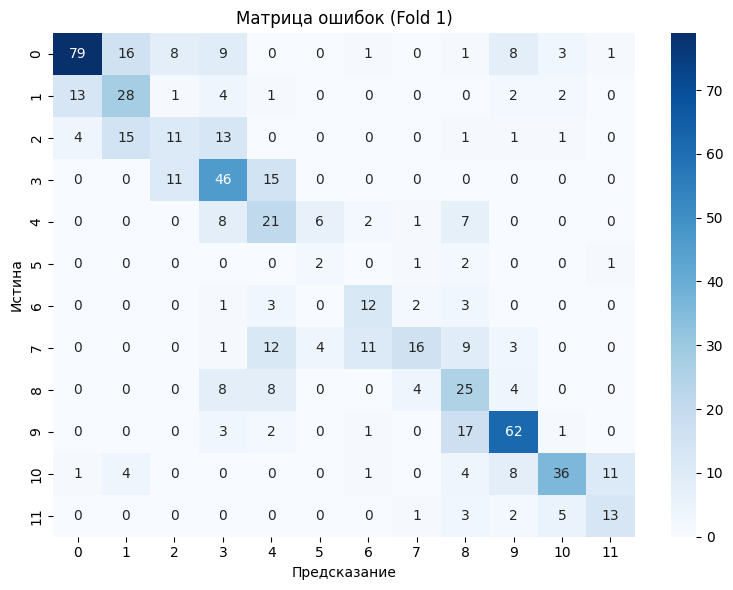

Fold 2
  Train wells: ['A1', 'A3', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'D1', 'E1']
  Val wells:   ['A2', 'C2', 'C7']
  Train: 2369 проб, Val: 658 проб
F1 macro (train): 0.9972
F1 macro (val):   0.6318
Gap (train-val):  0.3654

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.8667    0.9286    0.8966        84
           1     0.3600    0.4737    0.4091        19
           2     0.8148    0.5000    0.6197        44
           3     0.8000    0.7879    0.7939        66
           4     0.7000    0.7467    0.7226        75
           5     0.4000    0.2941    0.3390        34
           6     0.5484    0.5312    0.5397        32
           7     0.4062    0.3514    0.3768        37
           8     0.5340    0.6322    0.5789        87
           9     0.7685    0.6860    0.7249       121
          10     0.5957    0.8000    0.6829        35
          11     0.8800    0.9167    0.8980        24

    accuracy                    

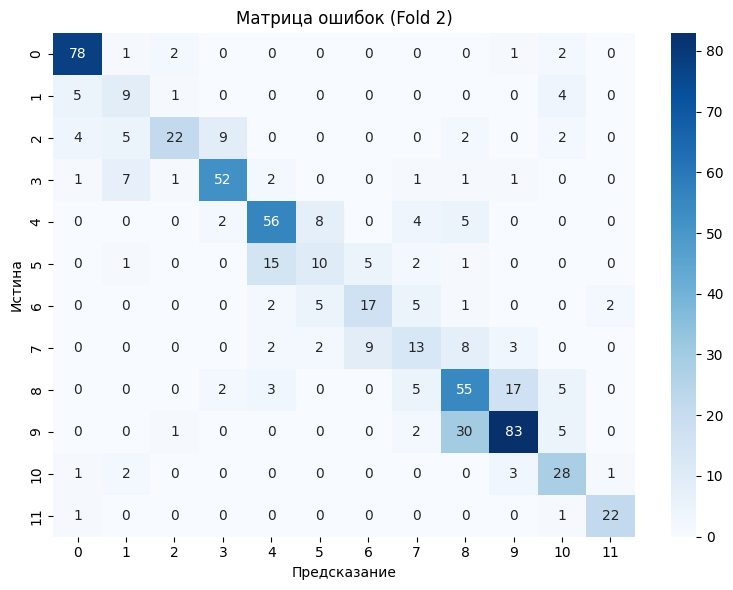

Fold 3
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A3', 'C1', 'C5']
  Train: 2428 проб, Val: 599 проб
F1 macro (train): 0.9969
F1 macro (val):   0.5328
Gap (train-val):  0.4641

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.8429    0.9440    0.8906       125
           1     0.5217    0.3333    0.4068        36
           2     0.7200    0.5625    0.6316        32
           3     0.4773    0.7000    0.5676        30
           4     0.5641    0.6111    0.5867        36
           5     0.3077    0.1111    0.1633        36
           6     0.3333    0.2121    0.2593        33
           7     0.3333    0.2750    0.3014        40
           8     0.5395    0.4659    0.5000        88
           9     0.5556    0.7692    0.6452        78
          10     0.7111    0.7111    0.7111        45
          11     0.5938    0.9500    0.7308        20

    accuracy                    

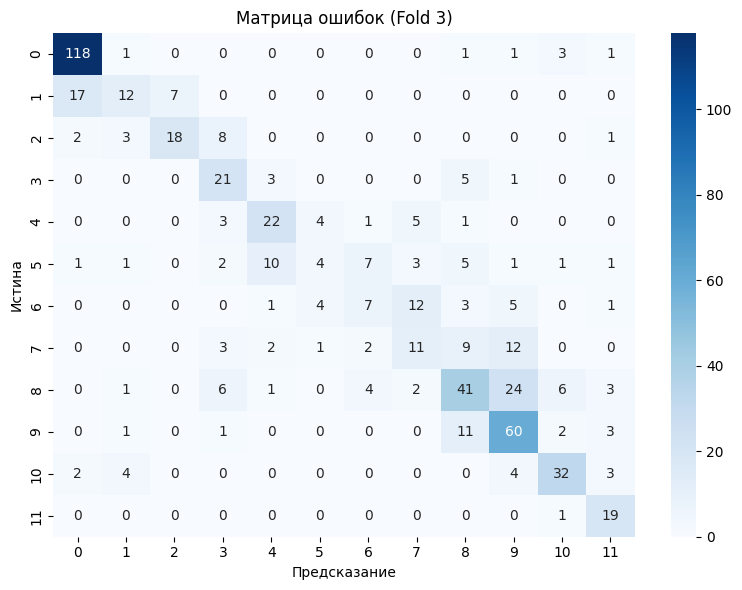

Fold 4
  Train wells: ['A1', 'A2', 'A3', 'A4', 'C1', 'C2', 'C4', 'C5', 'C6', 'C7', 'E1']
  Val wells:   ['B1', 'C3', 'D1']
  Train: 2465 проб, Val: 562 проб
F1 macro (train): 0.9958
F1 macro (val):   0.5541
Gap (train-val):  0.4417

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.8182    0.9419    0.8757        86
           1     0.5000    0.2941    0.3704        34
           2     0.4634    0.5135    0.4872        37
           3     0.7018    0.6349    0.6667        63
           4     0.6250    0.6250    0.6250        48
           5     0.5000    0.2000    0.2857        35
           6     0.3478    0.3478    0.3478        23
           7     0.4783    0.2895    0.3607        38
           8     0.3774    0.3279    0.3509        61
           9     0.5577    0.9206    0.6946        63
          10     0.7500    0.8372    0.7912        43
          11     0.7812    0.8065    0.7937        31

    accuracy                    

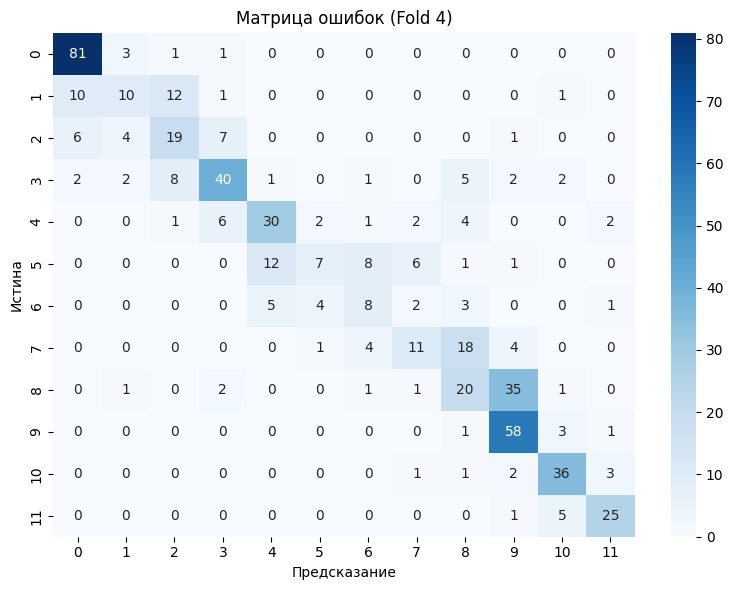

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'B1', 'C1', 'C2', 'C3', 'C5', 'C7', 'D1', 'E1']
  Val wells:   ['A4', 'C4', 'C6']
  Train: 2466 проб, Val: 561 проб
F1 macro (train): 0.9947
F1 macro (val):   0.4682
Gap (train-val):  0.5265

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.3421    0.9630    0.5049        27
           1     0.5385    0.4375    0.4828        16
           2     0.7222    0.5652    0.6341        23
           3     0.6154    0.6667    0.6400        36
           4     0.4222    0.6786    0.5205        28
           5     0.0833    0.0455    0.0588        22
           6     0.3684    0.3182    0.3415        22
           7     0.2500    0.2609    0.2553        23
           8     0.5443    0.5375    0.5409        80
           9     0.5969    0.6364    0.6160       121
          10     0.6310    0.6709    0.6503        79
          11     0.8696    0.2381    0.3738        84

    accuracy                    

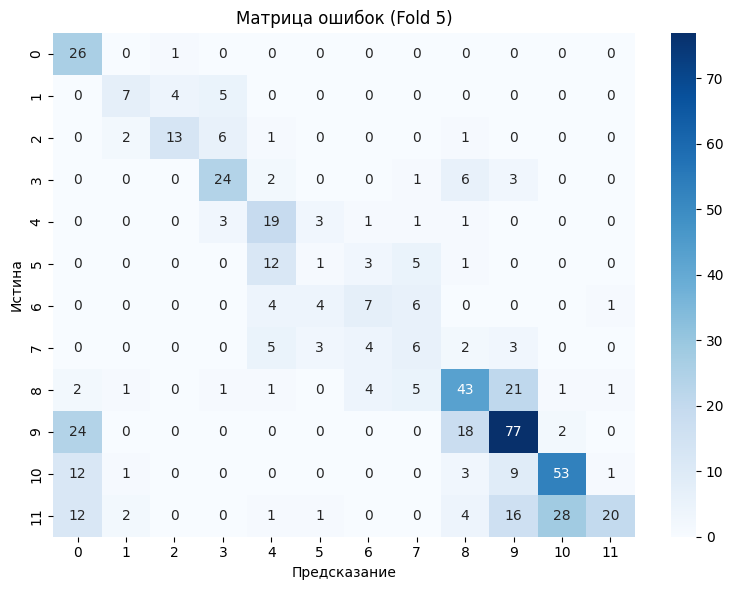

Результаты кросс-валидации
  Fold 1: F1_macro = 0.4848
  Fold 2: F1_macro = 0.6318
  Fold 3: F1_macro = 0.5328
  Fold 4: F1_macro = 0.5541
  Fold 5: F1_macro = 0.4682

  Средний F1 macro: 0.5344 ± 0.0578

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.7610    0.8527    0.8042       448
           1     0.4583    0.4231    0.4400       156
           2     0.5845    0.4560    0.5123       182
           3     0.6141    0.6854    0.6478       267
           4     0.5401    0.6379    0.5850       232
           5     0.3158    0.1805    0.2297       133
           6     0.4180    0.3893    0.4032       131
           7     0.4161    0.2938    0.3444       194
           8     0.4804    0.5041    0.4920       365
           9     0.6308    0.7249    0.6746       469
          10     0.6801    0.6929    0.6865       267
          11     0.7174    0.5410    0.6168       183

    accuracy                         0.5953      

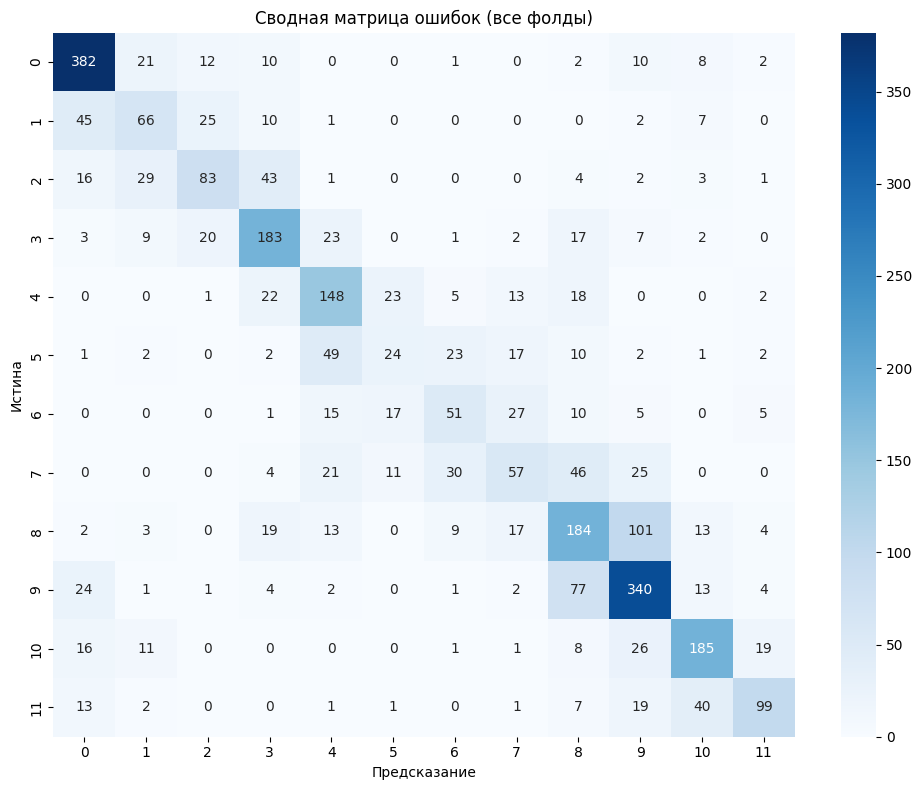

/tmp/ipykernel_313437/1782897511.py:133: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exc

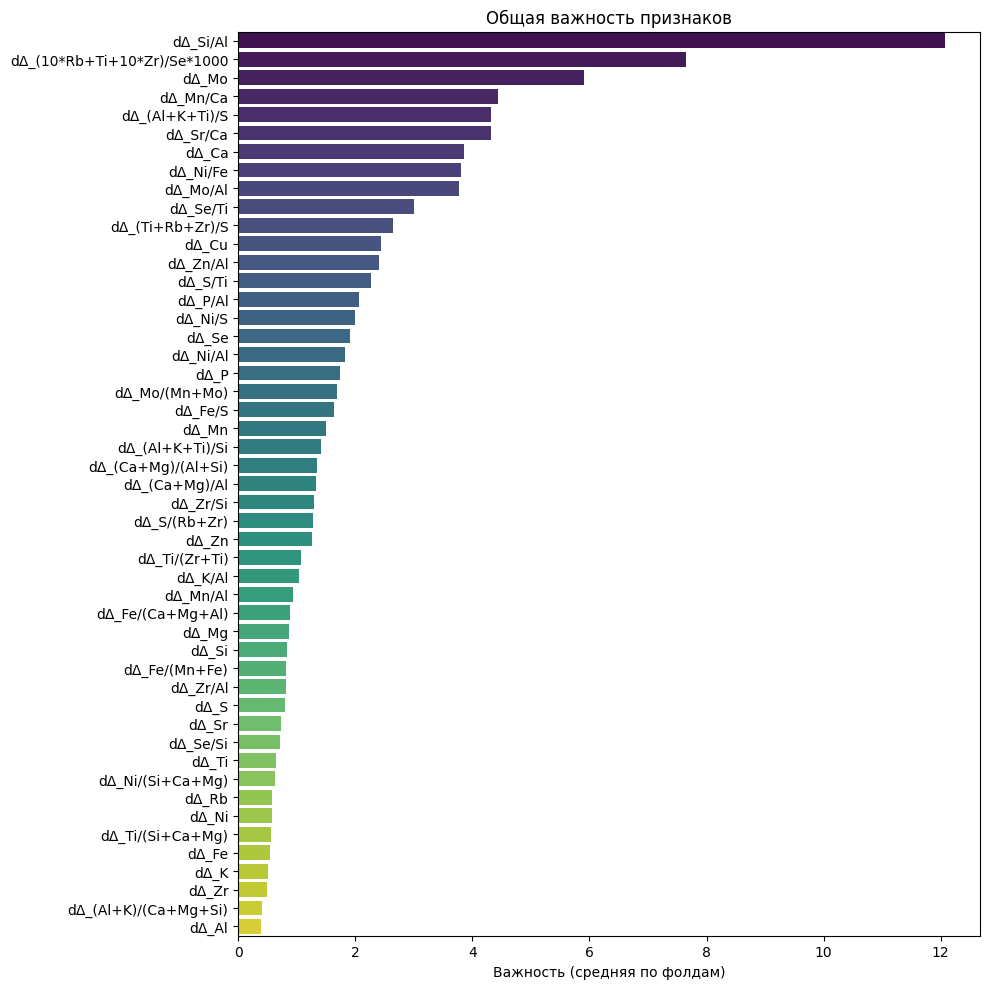

In [73]:
X = df[features]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42,
    'task_type': 'GPU',
    'devices': '0'
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []

# Накопители для SHAP и важности
shap_all = []           # список массивов (n_val_samples, n_classes, n_features)
importance_all = []      # список массивов (n_features,) — важность от каждой модели

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    # shap_values: (n_samples, n_classes, n_features + 1)
    shap_per_class = shap_values[:, :, :-1]  # (n_samples, n_classes, n_features)
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Сохранение в CSV
# results_df = pd.concat(results_df_list, ignore_index=True)
# results_df.to_csv('Result/classification_results_CatBoost_fixed_elements_ratios.csv', index=False)

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")
print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(features, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()

**Рассчет скользящих z-score с окном k=5, по каждой скважине отдельно**

In [74]:
features = [
    'Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
    'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo',
    '(Ca+Mg)/(Al+Si)',
    'Sr/Ca',
    'Mn/Ca',
    '(Al+K)/(Ca+Mg+Si)',
    'Zr/Al',
    'Zr/Si',
    'K/Al',
    'Ti/(Zr+Ti)',
    'Si/Al',
    'P/Al',
    'Ni/Fe',
    'Ni/(Si+Ca+Mg)',
    'S/(Rb+Zr)',
    'Mo/Al',
    'Mo/(Mn+Mo)',
    'Mn/Al',
    'Fe/S',
    'Ni/S',
    'Fe/(Ca+Mg+Al)',
    'Ti/(Si+Ca+Mg)',
    'Fe/(Mn+Fe)',
    '(Al+K+Ti)/Si',
    '(Al+K+Ti)/S',
    '(Ti+Rb+Zr)/S',
    'S/Ti',
    'Ni/Al',
    'Zn/Al',
    'Se/Si',
    '(Ca+Mg)/Al',
    'Se/Ti',
    '(10*Rb+Ti+10*Zr)/Se*1000'
]

In [75]:
# z = (x - rolling_mean) / rolling_std

k = 5

# Сортируем по скважине и глубине
df_sorted = df.sort_values(['Well', 'Depth']).reset_index(drop=True)

zscore_features = []
for col in features:
    z_col = f'z5_{col}'
    rolling = df_sorted.groupby('Well')[col].rolling(window=k, center=True, min_periods=3)
    df_sorted[z_col] = (df_sorted[col] - rolling.mean().reset_index(level=0, drop=True)) / \
                       rolling.std().reset_index(level=0, drop=True)
    zscore_features.append(z_col)

# Возвращаем исходный порядок
df = df_sorted.sort_values('index' if 'index' in df_sorted.columns else df_sorted.columns[0]).reset_index(drop=True)

print(f"Добавлено z-score признаков: {len(zscore_features)}")
print(f"Примеры: {zscore_features[:5]}")


Добавлено z-score признаков: 49
Примеры: ['z5_Mg', 'z5_Al', 'z5_Si', 'z5_P', 'z5_S']


In [76]:
print(df.columns.tolist())

['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo', 'Well', 'Sample', 'Depth', 'Stratigraphy', 'Strat', '(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)', 'Zr/Al', 'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)', 'Si/Al', 'P/Al', 'Ni/Fe', 'Ni/(Si+Ca+Mg)', 'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al', 'Fe/S', 'Ni/S', 'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)', '(Al+K+Ti)/Si', '(Al+K+Ti)/S', '(Ti+Rb+Zr)/S', 'S/Ti', 'Ni/Al', 'Zn/Al', 'Se/Si', '(Ca+Mg)/Al', 'Se/Ti', '(10*Rb+Ti+10*Zr)/Se*1000', 'dΔ_Mg', 'dΔ_Al', 'dΔ_Si', 'dΔ_P', 'dΔ_S', 'dΔ_K', 'dΔ_Ca', 'dΔ_Ti', 'dΔ_Mn', 'dΔ_Fe', 'dΔ_Ni', 'dΔ_Cu', 'dΔ_Zn', 'dΔ_Se', 'dΔ_Rb', 'dΔ_Sr', 'dΔ_Zr', 'dΔ_Mo', 'dΔ_(Ca+Mg)/(Al+Si)', 'dΔ_Sr/Ca', 'dΔ_Mn/Ca', 'dΔ_(Al+K)/(Ca+Mg+Si)', 'dΔ_Zr/Al', 'dΔ_Zr/Si', 'dΔ_K/Al', 'dΔ_Ti/(Zr+Ti)', 'dΔ_Si/Al', 'dΔ_P/Al', 'dΔ_Ni/Fe', 'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_S/(Rb+Zr)', 'dΔ_Mo/Al', 'dΔ_Mo/(Mn+Mo)', 'dΔ_Mn/Al', 'dΔ_Fe/S', 'dΔ_Ni/S', 'dΔ_Fe/(Ca+Mg+Al)', 'dΔ_Ti/(Si+Ca+Mg)', 'dΔ_

In [77]:
features = ['z5_Mg', 'z5_Al', 'z5_Si', 'z5_P', 'z5_S', 'z5_K', 'z5_Ca', 
            'z5_Ti', 'z5_Mn', 'z5_Fe', 'z5_Ni', 'z5_Cu', 'z5_Zn', 'z5_Se', 
            'z5_Rb', 'z5_Sr', 'z5_Zr', 'z5_Mo', 'z5_(Ca+Mg)/(Al+Si)', 'z5_Sr/Ca', 
            'z5_Mn/Ca', 'z5_(Al+K)/(Ca+Mg+Si)', 'z5_Zr/Al', 'z5_Zr/Si', 'z5_K/Al', 
            'z5_Ti/(Zr+Ti)', 'z5_Si/Al', 'z5_P/Al', 'z5_Ni/Fe', 'z5_Ni/(Si+Ca+Mg)', 
            'z5_S/(Rb+Zr)', 'z5_Mo/Al', 'z5_Mo/(Mn+Mo)', 'z5_Mn/Al', 'z5_Fe/S', 'z5_Ni/S', 
            'z5_Fe/(Ca+Mg+Al)', 'z5_Ti/(Si+Ca+Mg)', 'z5_Fe/(Mn+Fe)', 'z5_(Al+K+Ti)/Si', 
            'z5_(Al+K+Ti)/S', 'z5_(Ti+Rb+Zr)/S', 'z5_S/Ti', 'z5_Ni/Al', 'z5_Zn/Al', 
            'z5_Se/Si', 'z5_(Ca+Mg)/Al', 'z5_Se/Ti', 'z5_(10*Rb+Ti+10*Zr)/Se*1000'
]

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2380 проб, Val: 647 проб
F1 macro (train): 0.9987
F1 macro (val):   0.2926
Gap (train-val):  0.7061

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.5242    0.5159    0.5200       126
           1     0.3871    0.2353    0.2927        51
           2     0.3077    0.0870    0.1356        46
           3     0.4773    0.2917    0.3621        72
           4     0.3333    0.3333    0.3333        45
           5     0.0000    0.0000    0.0000         6
           6     0.2400    0.2857    0.2609        21
           7     0.5000    0.1250    0.2000        56
           8     0.1587    0.2041    0.1786        49
           9     0.3512    0.6860    0.4646        86
          10     0.5882    0.3077    0.4040        65
          11     0.2462    0.6667    0.3596        24

    accuracy                    

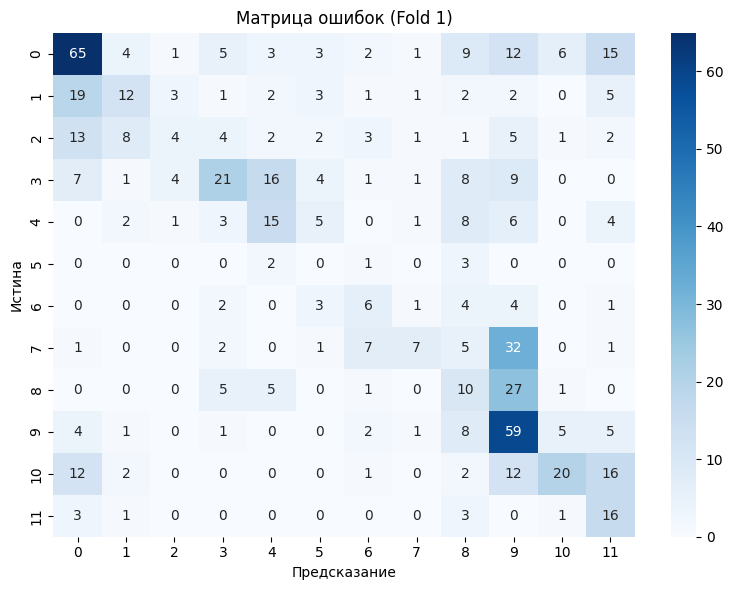

Fold 2
  Train wells: ['A1', 'A3', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'D1', 'E1']
  Val wells:   ['A2', 'C2', 'C7']
  Train: 2369 проб, Val: 658 проб
F1 macro (train): 0.9987
F1 macro (val):   0.4056
Gap (train-val):  0.5932

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.6019    0.7381    0.6631        84
           1     0.3846    0.2632    0.3125        19
           2     0.2973    0.2500    0.2716        44
           3     0.3562    0.3939    0.3741        66
           4     0.5513    0.5733    0.5621        75
           5     0.2500    0.0588    0.0952        34
           6     0.6364    0.2188    0.3256        32
           7     0.3056    0.2973    0.3014        37
           8     0.5301    0.5057    0.5176        87
           9     0.5461    0.6860    0.6081       121
          10     0.3333    0.4571    0.3855        35
          11     0.5625    0.3750    0.4500        24

    accuracy                    

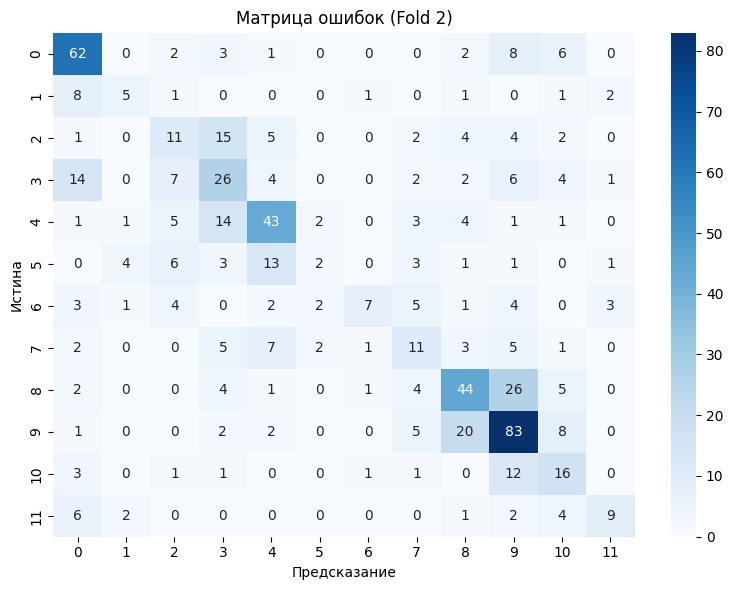

Fold 3
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A3', 'C1', 'C5']
  Train: 2428 проб, Val: 599 проб
F1 macro (train): 0.9988
F1 macro (val):   0.3546
Gap (train-val):  0.6441

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.7500    0.6480    0.6953       125
           1     0.4375    0.1944    0.2692        36
           2     0.3750    0.2812    0.3214        32
           3     0.4545    0.5000    0.4762        30
           4     0.3953    0.4722    0.4304        36
           5     0.1429    0.0278    0.0465        36
           6     0.2222    0.1212    0.1569        33
           7     0.2500    0.1000    0.1429        40
           8     0.4200    0.4773    0.4468        88
           9     0.3475    0.6282    0.4475        78
          10     0.4800    0.5333    0.5053        45
          11     0.2326    0.5000    0.3175        20

    accuracy                    

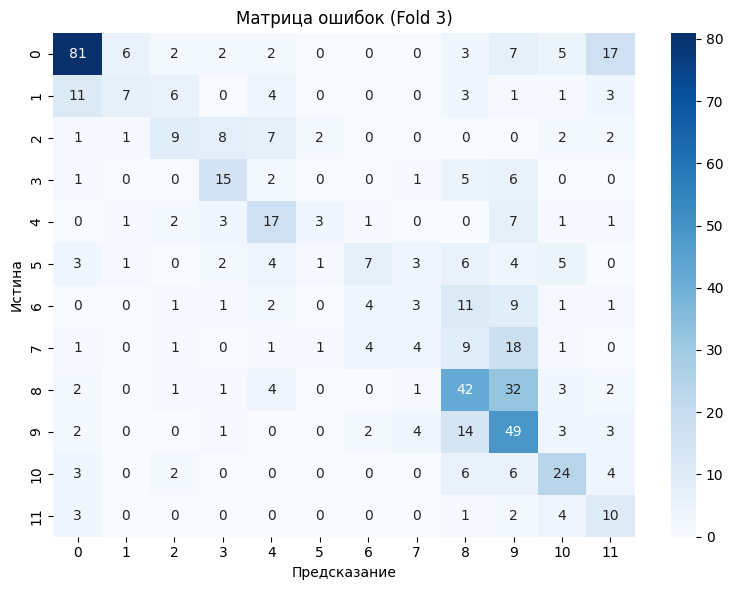

Fold 4
  Train wells: ['A1', 'A2', 'A3', 'A4', 'C1', 'C2', 'C4', 'C5', 'C6', 'C7', 'E1']
  Val wells:   ['B1', 'C3', 'D1']
  Train: 2465 проб, Val: 562 проб
F1 macro (train): 0.9989
F1 macro (val):   0.3434
Gap (train-val):  0.6555

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.4768    0.8372    0.6076        86
           1     0.3333    0.0882    0.1395        34
           2     0.3226    0.2703    0.2941        37
           3     0.4250    0.2698    0.3301        63
           4     0.6047    0.5417    0.5714        48
           5     0.4000    0.0571    0.1000        35
           6     0.0435    0.0435    0.0435        23
           7     0.2500    0.1316    0.1724        38
           8     0.2969    0.3115    0.3040        61
           9     0.4022    0.5873    0.4774        63
          10     0.5357    0.6977    0.6061        43
          11     0.5000    0.4516    0.4746        31

    accuracy                    

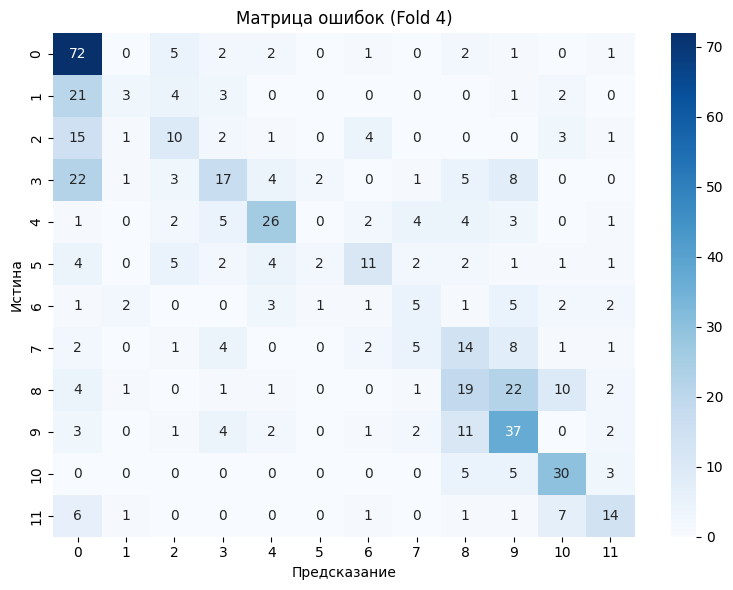

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'B1', 'C1', 'C2', 'C3', 'C5', 'C7', 'D1', 'E1']
  Val wells:   ['A4', 'C4', 'C6']
  Train: 2466 проб, Val: 561 проб
F1 macro (train): 0.9990
F1 macro (val):   0.2908
Gap (train-val):  0.7082

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.2366    0.8148    0.3667        27
           1     0.2308    0.1875    0.2069        16
           2     0.4167    0.2174    0.2857        23
           3     0.3514    0.3611    0.3562        36
           4     0.2593    0.5000    0.3415        28
           5     0.1250    0.0909    0.1053        22
           6     0.3571    0.2273    0.2778        22
           7     0.0667    0.0870    0.0755        23
           8     0.3826    0.5500    0.4513        80
           9     0.3920    0.4050    0.3984       121
          10     0.5676    0.2658    0.3621        79
          11     0.8667    0.1548    0.2626        84

    accuracy                    

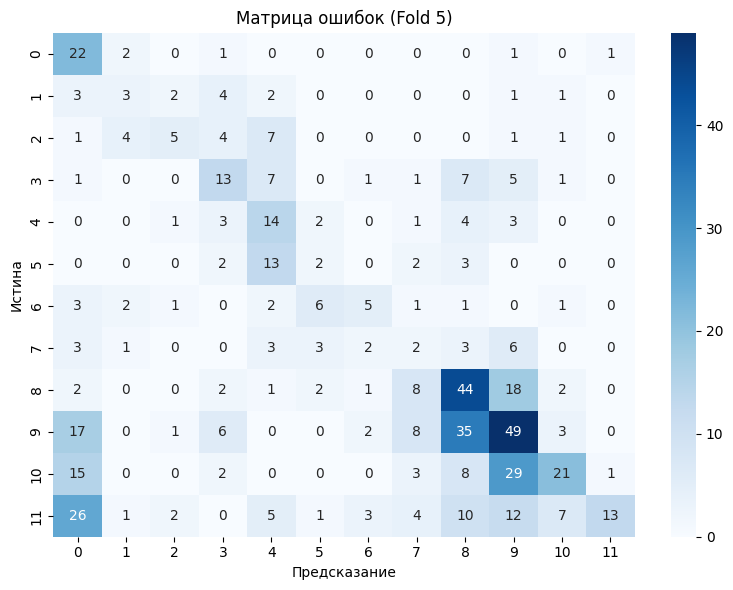

Результаты кросс-валидации
  Fold 1: F1_macro = 0.2926
  Fold 2: F1_macro = 0.4056
  Fold 3: F1_macro = 0.3546
  Fold 4: F1_macro = 0.3434
  Fold 5: F1_macro = 0.2908

  Средний F1 macro: 0.3374 ± 0.0428

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.5216    0.6741    0.5881       448
           1     0.3659    0.1923    0.2521       156
           2     0.3333    0.2143    0.2609       182
           3     0.4053    0.3446    0.3725       267
           4     0.4373    0.4957    0.4646       232
           5     0.1228    0.0526    0.0737       133
           6     0.2527    0.1756    0.2072       131
           7     0.2500    0.1495    0.1871       194
           8     0.3741    0.4356    0.4025       365
           9     0.4086    0.5906    0.4830       469
          10     0.4933    0.4157    0.4512       267
          11     0.3713    0.3388    0.3543       183

    accuracy                         0.4116      

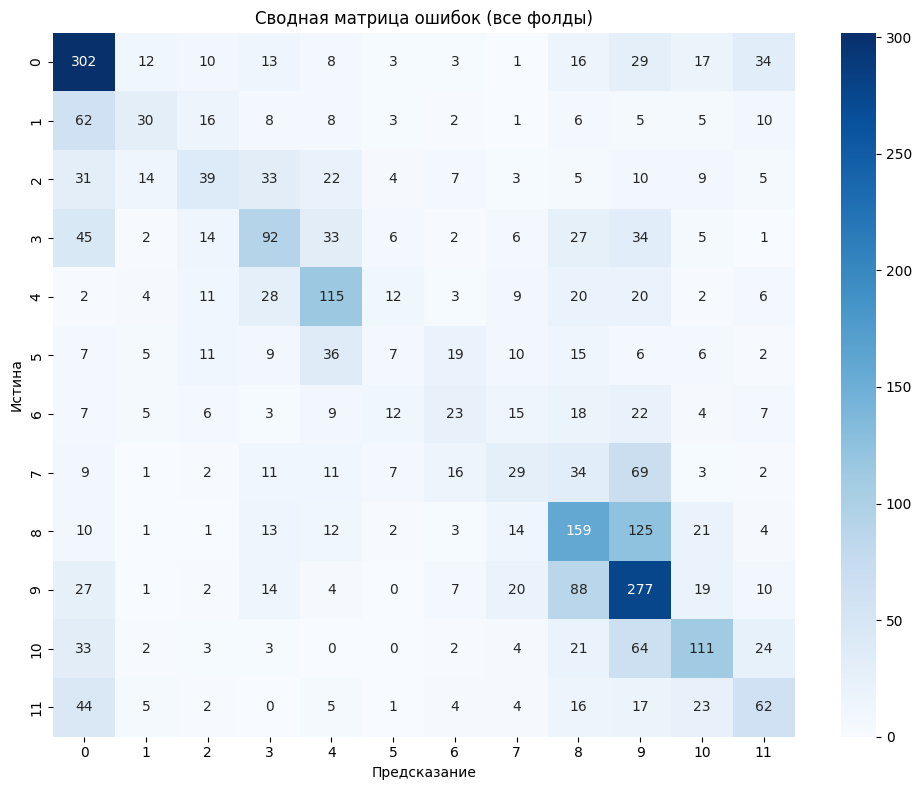

/tmp/ipykernel_313437/1782897511.py:133: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exc

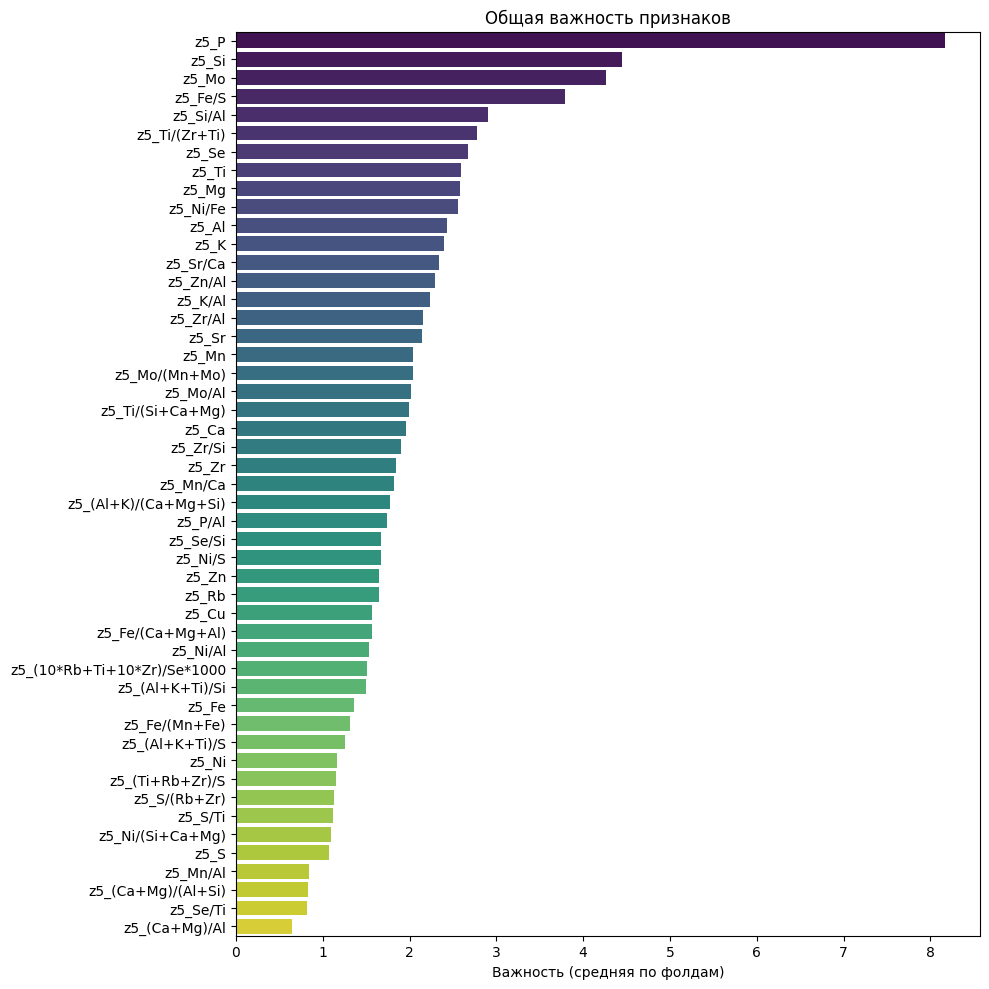

In [78]:
X = df[features]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42,
    'task_type': 'GPU',
    'devices': '0'
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []

# Накопители для SHAP и важности
shap_all = []           # список массивов (n_val_samples, n_classes, n_features)
importance_all = []      # список массивов (n_features,) — важность от каждой модели

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    # shap_values: (n_samples, n_classes, n_features + 1)
    shap_per_class = shap_values[:, :, :-1]  # (n_samples, n_classes, n_features)
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Сохранение в CSV
# results_df = pd.concat(results_df_list, ignore_index=True)
# results_df.to_csv('Result/classification_results_CatBoost_fixed_elements_ratios.csv', index=False)

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")
print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(features, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()

**Создание относительных градиентов rΔxi = xi / (xi-1 + epsilon)**

In [79]:
features = [
    'Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe',
    'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo',
    '(Ca+Mg)/(Al+Si)',
    'Sr/Ca',
    'Mn/Ca',
    '(Al+K)/(Ca+Mg+Si)',
    'Zr/Al',
    'Zr/Si',
    'K/Al',
    'Ti/(Zr+Ti)',
    'Si/Al',
    'P/Al',
    'Ni/Fe',
    'Ni/(Si+Ca+Mg)',
    'S/(Rb+Zr)',
    'Mo/Al',
    'Mo/(Mn+Mo)',
    'Mn/Al',
    'Fe/S',
    'Ni/S',
    'Fe/(Ca+Mg+Al)',
    'Ti/(Si+Ca+Mg)',
    'Fe/(Mn+Fe)',
    '(Al+K+Ti)/Si',
    '(Al+K+Ti)/S',
    '(Ti+Rb+Zr)/S',
    'S/Ti',
    'Ni/Al',
    'Zn/Al',
    'Se/Si',
    '(Ca+Mg)/Al',
    'Se/Ti',
    '(10*Rb+Ti+10*Zr)/Se*1000'
]

In [80]:
df = df.sort_values(['Well', 'Depth']).reset_index(drop=True)

rgrad_features = []
for col in features:
    rgrad_col = f'rΔ_{col}'
    prev = df.groupby('Well')[col].shift(1)
    epsilon = df[col].median() * 0.01
    df[rgrad_col] = df[col] / (prev + epsilon)
    rgrad_features.append(rgrad_col)

print(f"Добавлено в df: {len(rgrad_features)} признаков")
print(f"Всего колонок: {len(df.columns)}")


Добавлено в df: 49 признаков
Всего колонок: 201


In [81]:
print(df.columns.tolist())

['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo', 'Well', 'Sample', 'Depth', 'Stratigraphy', 'Strat', '(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)', 'Zr/Al', 'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)', 'Si/Al', 'P/Al', 'Ni/Fe', 'Ni/(Si+Ca+Mg)', 'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al', 'Fe/S', 'Ni/S', 'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)', '(Al+K+Ti)/Si', '(Al+K+Ti)/S', '(Ti+Rb+Zr)/S', 'S/Ti', 'Ni/Al', 'Zn/Al', 'Se/Si', '(Ca+Mg)/Al', 'Se/Ti', '(10*Rb+Ti+10*Zr)/Se*1000', 'dΔ_Mg', 'dΔ_Al', 'dΔ_Si', 'dΔ_P', 'dΔ_S', 'dΔ_K', 'dΔ_Ca', 'dΔ_Ti', 'dΔ_Mn', 'dΔ_Fe', 'dΔ_Ni', 'dΔ_Cu', 'dΔ_Zn', 'dΔ_Se', 'dΔ_Rb', 'dΔ_Sr', 'dΔ_Zr', 'dΔ_Mo', 'dΔ_(Ca+Mg)/(Al+Si)', 'dΔ_Sr/Ca', 'dΔ_Mn/Ca', 'dΔ_(Al+K)/(Ca+Mg+Si)', 'dΔ_Zr/Al', 'dΔ_Zr/Si', 'dΔ_K/Al', 'dΔ_Ti/(Zr+Ti)', 'dΔ_Si/Al', 'dΔ_P/Al', 'dΔ_Ni/Fe', 'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_S/(Rb+Zr)', 'dΔ_Mo/Al', 'dΔ_Mo/(Mn+Mo)', 'dΔ_Mn/Al', 'dΔ_Fe/S', 'dΔ_Ni/S', 'dΔ_Fe/(Ca+Mg+Al)', 'dΔ_Ti/(Si+Ca+Mg)', 'dΔ_

In [82]:
df

,Mg,Al,Si,P,S,K,Ca,Ti,Mn,Fe,...,rΔ_(Al+K+Ti)/Si,rΔ_(Al+K+Ti)/S,rΔ_(Ti+Rb+Zr)/S,rΔ_S/Ti,rΔ_Ni/Al,rΔ_Zn/Al,rΔ_Se/Si,rΔ_(Ca+Mg)/Al,rΔ_Se/Ti,rΔ_(10*Rb+Ti+10*Zr)/Se*1000
0,1.681623,5.706609,20.809375,0.000239,4.883089,0.358961,0.191912,0.192320,0.002664,2.455414,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2.115326,4.681748,15.206337,0.000239,7.612235,0.274933,0.806966,0.159650,0.010551,4.272748,...,1.109426,0.518007,0.523867,1.866339,3.237942,5.727204,2.547699,1.876953,2.240152,0.429433
2,1.715452,4.620812,16.875374,0.000239,7.701370,0.243583,0.304632,0.155271,0.019363,4.095088,...,0.877422,0.947248,0.924579,1.036821,0.706369,0.199441,0.378171,0.695653,0.430601,2.142383
3,1.872067,5.503601,18.376529,0.000239,6.194391,0.398233,0.265514,0.173688,0.003095,3.032062,...,1.102026,1.468815,1.365850,0.716764,1.253908,1.507201,5.512075,0.879890,5.360662,0.195181
4,1.586948,4.797547,16.439092,0.000239,7.773937,0.291996,0.365831,0.165617,0.001955,4.114941,...,0.959514,0.678182,0.734913,1.310375,0.628004,0.602808,0.382185,1.036664,0.358433,2.546658
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3022,1.278100,8.616273,28.388951,0.007900,2.830361,2.901873,1.764976,0.510543,0.043224,3.233368,...,1.044678,0.378764,0.353717,2.623127,1.985757,0.181877,4.404691,0.565379,2.545351,0.062684
3023,1.309000,8.910452,26.883048,0.000239,5.503497,2.993462,0.962944,0.492751,0.045489,4.833295,...,1.081812,0.528033,0.494700,1.959074,1.274371,3.893828,2.175305,0.713373,1.866261,0.402540
3024,1.554100,8.413048,28.777198,0.023300,3.578398,2.912097,1.042116,0.470768,0.037091,3.431198,...,0.884020,1.453145,1.462543,0.671116,0.714024,1.166582,0.365757,1.190475,0.385030,2.321634
3025,0.941500,7.412025,30.434881,0.086501,3.803724,2.449646,1.119981,0.389820,0.033599,3.716377,...,0.816656,0.813648,0.769808,1.257671,0.405323,0.240794,1.943966,0.889042,2.218288,0.330494


**Сохзранения датасета со всеми новыми признаками**

In [83]:
df.to_csv('Data/data_kern_ALLratios_16_10.csv', index=False)

print(f"сохранено: ML_for_geochemistry/Data/data_kern_ALLratios_16_10.csv")
print(f"проб: {len(df)}")
print(f"колонок: {len(df.columns)}")

сохранено: ML_for_geochemistry/Data/data_kern_ALLratios_16_10.csv
проб: 3027
колонок: 201


In [51]:
features = ['rΔ_Mg', 'rΔ_Al', 'rΔ_Si', 'rΔ_P', 'rΔ_S', 'rΔ_K', 'rΔ_Ca', 
            'rΔ_Ti', 'rΔ_Mn', 'rΔ_Fe', 'rΔ_Ni', 'rΔ_Cu', 'rΔ_Zn', 'rΔ_Se', 
            'rΔ_Rb', 'rΔ_Sr', 'rΔ_Zr', 'rΔ_Mo', 'rΔ_(Ca+Mg)/(Al+Si)', 
            'rΔ_Sr/Ca', 'rΔ_Mn/Ca', 'rΔ_(Al+K)/(Ca+Mg+Si)', 'rΔ_Zr/Al', 
            'rΔ_Zr/Si', 'rΔ_K/Al', 'rΔ_Ti/(Zr+Ti)', 'rΔ_Si/Al', 'rΔ_P/Al', 
            'rΔ_Ni/Fe', 'rΔ_Ni/(Si+Ca+Mg)', 'rΔ_S/(Rb+Zr)', 'rΔ_Mo/Al', 
            'rΔ_Mo/(Mn+Mo)', 'rΔ_Mn/Al', 'rΔ_Fe/S', 'rΔ_Ni/S', 'rΔ_Fe/(Ca+Mg+Al)', 
            'rΔ_Ti/(Si+Ca+Mg)', 'rΔ_Fe/(Mn+Fe)', 'rΔ_(Al+K+Ti)/Si', 'rΔ_(Al+K+Ti)/S', 
            'rΔ_(Ti+Rb+Zr)/S', 'rΔ_S/Ti', 'rΔ_Ni/Al', 'rΔ_Zn/Al', 'rΔ_Se/Si', 
            'rΔ_(Ca+Mg)/Al', 'rΔ_Se/Ti', 'rΔ_(10*Rb+Ti+10*Zr)/Se*1000']

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2381 проб, Val: 647 проб
F1 macro (train): 0.9974
F1 macro (val):   0.3598
Gap (train-val):  0.6376

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.6897    0.4762    0.5634       126
           1     0.5769    0.2941    0.3896        51
           2     0.2353    0.0870    0.1270        46
           3     0.4839    0.4167    0.4478        72
           4     0.2424    0.3556    0.2883        45
           5     0.1250    0.5000    0.2000         6
           6     0.3333    0.3333    0.3333        21
           7     0.5789    0.1964    0.2933        56
           8     0.2258    0.2857    0.2523        49
           9     0.4400    0.7674    0.5593        86
          10     0.4667    0.4308    0.4480        65
          11     0.3019    0.6667    0.4156        24

    accuracy                    

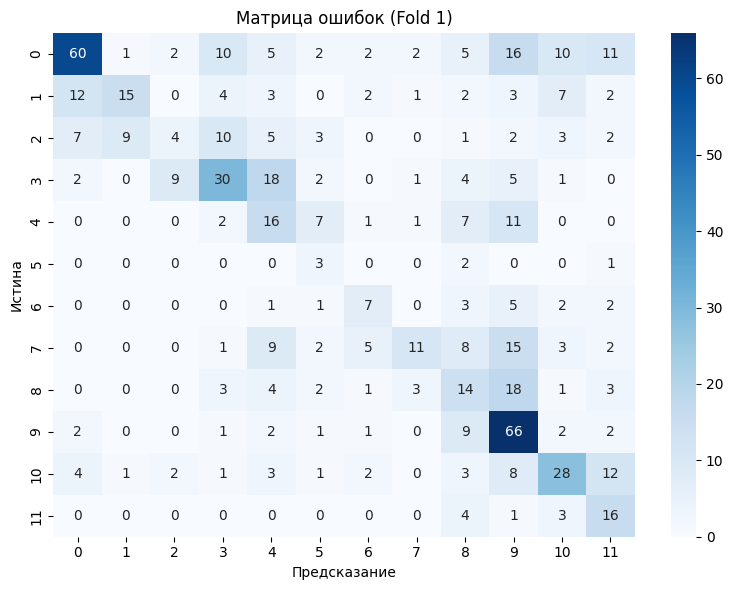

Fold 2
  Train wells: ['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'E1']
  Val wells:   ['C2', 'C7', 'D1']
  Train: 2370 проб, Val: 658 проб
F1 macro (train): 0.9963
F1 macro (val):   0.4683
Gap (train-val):  0.5280

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.7838    0.7768    0.7803       112
           1     0.1277    0.4286    0.1967        14
           2     0.5806    0.3913    0.4675        46
           3     0.6825    0.5584    0.6143        77
           4     0.5079    0.4706    0.4885        68
           5     0.4615    0.1333    0.2069        45
           6     0.2500    0.1852    0.2128        27
           7     0.4118    0.4516    0.4308        31
           8     0.4884    0.4941    0.4912        85
           9     0.6220    0.7117    0.6639       111
          10     0.2500    0.4545    0.3226        22
          11     0.6957    0.8000    0.7442        20

    accuracy                    

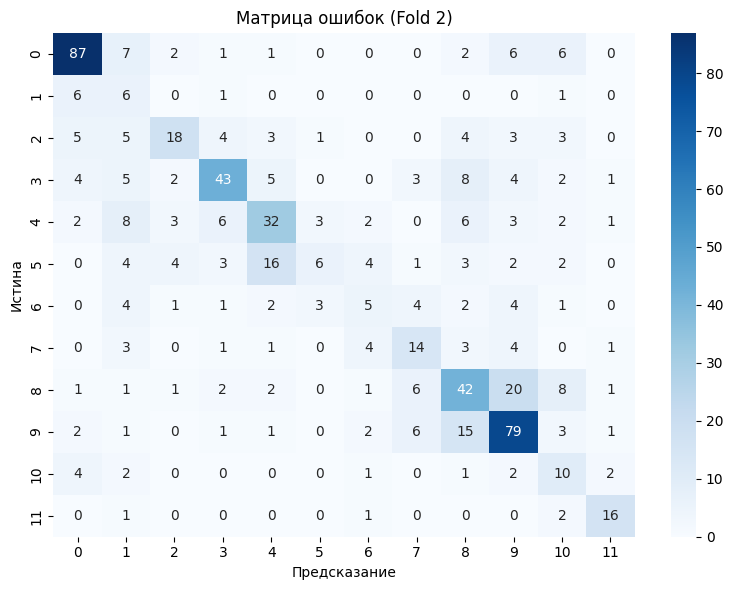

Fold 3
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A3', 'C1', 'C5']
  Train: 2429 проб, Val: 599 проб
F1 macro (train): 0.9949
F1 macro (val):   0.4096
Gap (train-val):  0.5854

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.8571    0.8160    0.8361       125
           1     0.5000    0.1944    0.2800        36
           2     0.4783    0.3438    0.4000        32
           3     0.2766    0.4333    0.3377        30
           4     0.4878    0.5556    0.5195        36
           5     0.1429    0.0278    0.0465        36
           6     0.1429    0.0909    0.1111        33
           7     0.3448    0.2500    0.2899        40
           8     0.4151    0.5000    0.4536        88
           9     0.3905    0.5256    0.4481        78
          10     0.5741    0.6889    0.6263        45
          11     0.4545    0.7500    0.5660        20

    accuracy                    

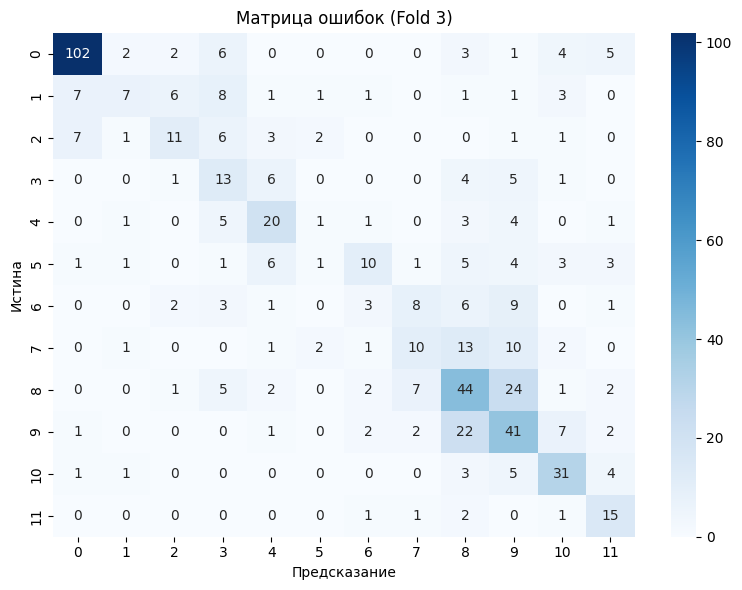

Fold 4
  Train wells: ['A1', 'A3', 'A4', 'C1', 'C2', 'C4', 'C5', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A2', 'B1', 'C3']
  Train: 2465 проб, Val: 563 проб
F1 macro (train): 0.9958
F1 macro (val):   0.4121
Gap (train-val):  0.5837

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.5714    0.8276    0.6761        58
           1     0.5500    0.2821    0.3729        39
           2     0.4571    0.4571    0.4571        35
           3     0.4792    0.4423    0.4600        52
           4     0.4103    0.2857    0.3368        56
           5     0.1333    0.0833    0.1026        24
           6     0.2581    0.2857    0.2712        28
           7     0.3000    0.1364    0.1875        44
           8     0.2353    0.2540    0.2443        63
           9     0.4690    0.7260    0.5699        73
          10     0.5873    0.6607    0.6218        56
          11     0.7407    0.5714    0.6452        35

    accuracy                    

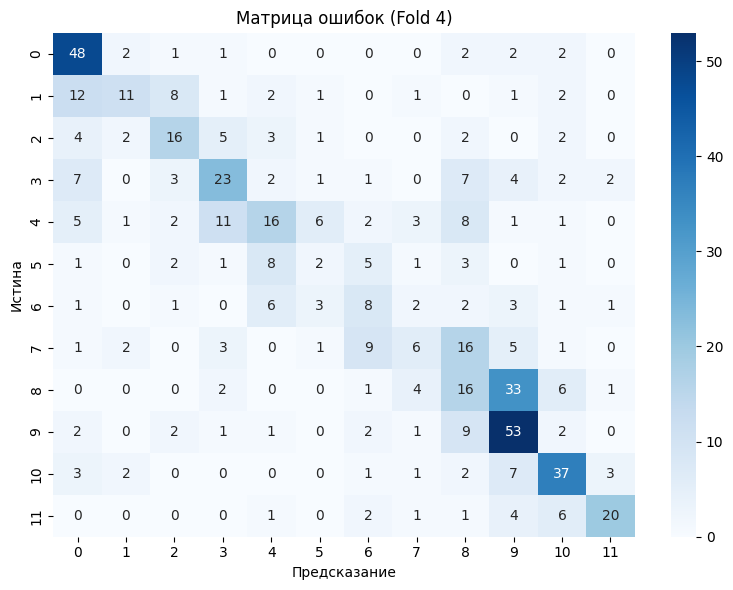

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'B1', 'C1', 'C2', 'C3', 'C5', 'C7', 'D1', 'E1']
  Val wells:   ['A4', 'C4', 'C6']
  Train: 2467 проб, Val: 561 проб
F1 macro (train): 0.9943
F1 macro (val):   0.3154
Gap (train-val):  0.6789

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.1797    0.8519    0.2968        27
           1     0.4000    0.2500    0.3077        16
           2     0.4706    0.3478    0.4000        23
           3     0.3824    0.3611    0.3714        36
           4     0.2432    0.3214    0.2769        28
           5     0.1176    0.0909    0.1026        22
           6     0.3684    0.3182    0.3415        22
           7     0.1333    0.0870    0.1053        23
           8     0.4433    0.5375    0.4859        80
           9     0.4677    0.4793    0.4735       121
          10     0.5556    0.3797    0.4511        79
          11     0.8889    0.0952    0.1720        84

    accuracy                    

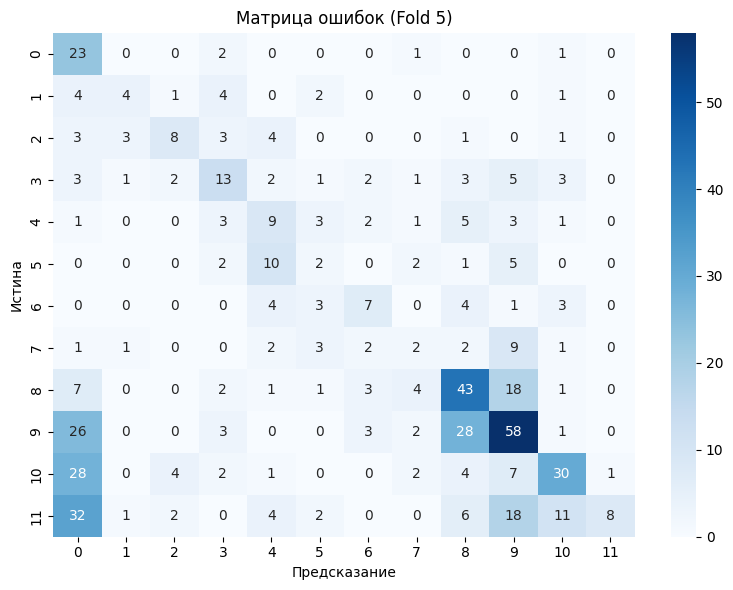

Результаты кросс-валидации
  Fold 1: F1_macro = 0.3598
  Fold 2: F1_macro = 0.4683
  Fold 3: F1_macro = 0.4096
  Fold 4: F1_macro = 0.4121
  Fold 5: F1_macro = 0.3154

  Средний F1 macro: 0.3930 ± 0.0518

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.6049    0.7143    0.6551       448
           1     0.3675    0.2756    0.3150       156
           2     0.4634    0.3132    0.3738       182
           3     0.4803    0.4569    0.4683       267
           4     0.3780    0.3991    0.3883       233
           5     0.1842    0.1053    0.1340       133
           6     0.2679    0.2290    0.2469       131
           7     0.3675    0.2216    0.2765       194
           8     0.3795    0.4356    0.4056       365
           9     0.4798    0.6333    0.5460       469
          10     0.5018    0.5094    0.5056       267
          11     0.5172    0.4098    0.4573       183

    accuracy                         0.4587      

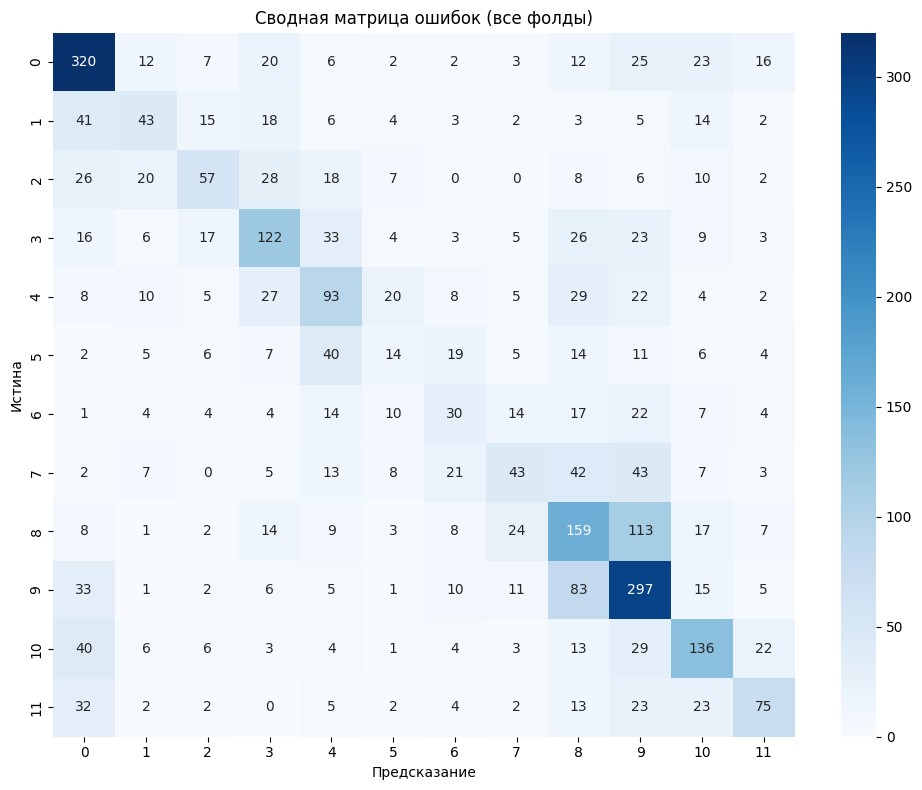

/tmp/ipykernel_313437/1782897511.py:133: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exc

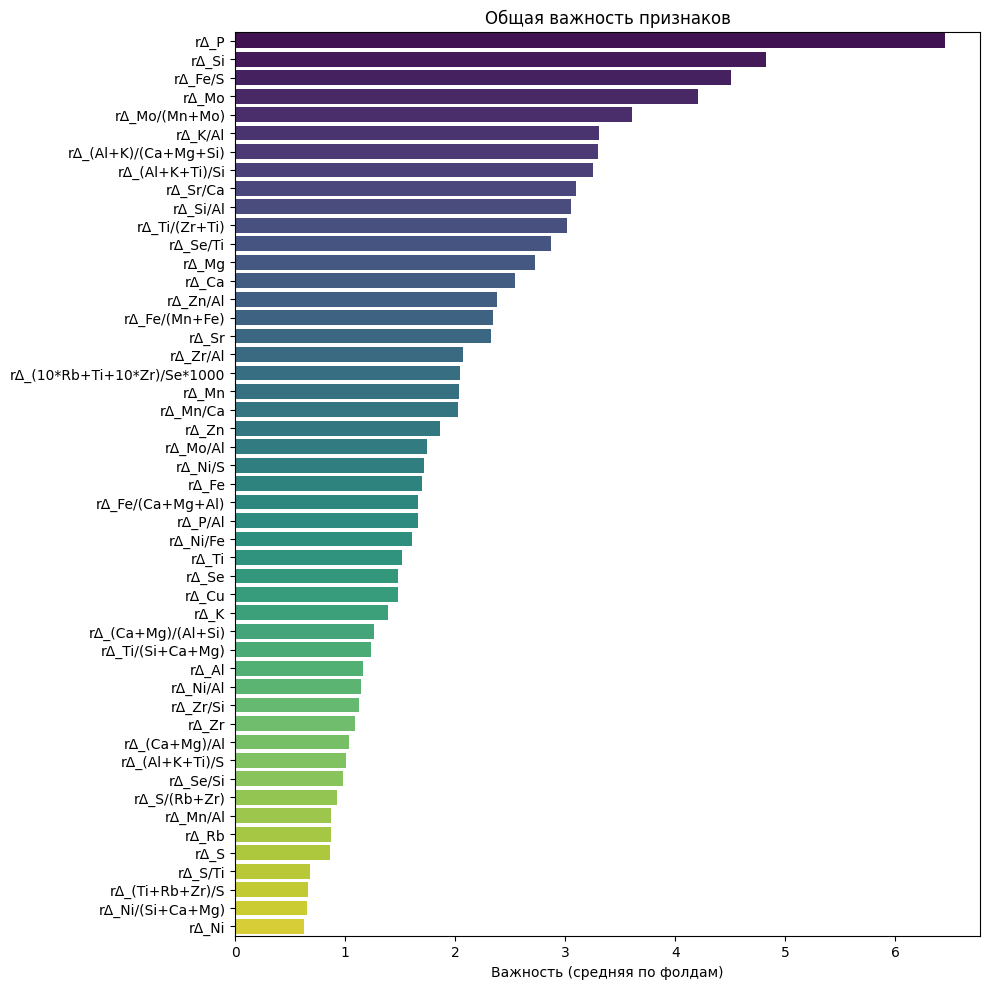

In [52]:
X = df[features]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42,
    'task_type': 'GPU',
    'devices': '0'
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []

# Накопители для SHAP и важности
shap_all = []           # список массивов (n_val_samples, n_classes, n_features)
importance_all = []      # список массивов (n_features,) — важность от каждой модели

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    # shap_values: (n_samples, n_classes, n_features + 1)
    shap_per_class = shap_values[:, :, :-1]  # (n_samples, n_classes, n_features)
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Сохранение в CSV
# results_df = pd.concat(results_df_list, ignore_index=True)
# results_df.to_csv('Result/classification_results_CatBoost_fixed_elements_ratios.csv', index=False)

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")
print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(features, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()

In [53]:
features = ['Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 
            'Fe', 'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 
            'Mo', '(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)', 
            'Zr/Al', 'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)', 'Si/Al', 'P/Al', 'Ni/Fe', 
            'Ni/(Si+Ca+Mg)', 'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al', 
            'Fe/S', 'Ni/S', 'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)', 
            '(Al+K+Ti)/Si', '(Al+K+Ti)/S', '(Ti+Rb+Zr)/S', 'S/Ti', 'Ni/Al', 
            'Zn/Al', 'Se/Si', '(Ca+Mg)/Al', 'Se/Ti', '(10*Rb+Ti+10*Zr)/Se*1000', 
            'dΔ_Mg', 'dΔ_Al', 'dΔ_Si', 'dΔ_P', 'dΔ_S', 'dΔ_K', 'dΔ_Ca', 'dΔ_Ti', 
            'dΔ_Mn', 'dΔ_Fe', 'dΔ_Ni', 'dΔ_Cu', 'dΔ_Zn', 'dΔ_Se', 'dΔ_Rb', 'dΔ_Sr', 
            'dΔ_Zr', 'dΔ_Mo', 'dΔ_(Ca+Mg)/(Al+Si)', 'dΔ_Sr/Ca', 'dΔ_Mn/Ca', 'dΔ_(Al+K)/(Ca+Mg+Si)', 
            'dΔ_Zr/Al', 'dΔ_Zr/Si', 'dΔ_K/Al', 'dΔ_Ti/(Zr+Ti)', 'dΔ_Si/Al', 'dΔ_P/Al', 'dΔ_Ni/Fe', 
            'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_S/(Rb+Zr)', 'dΔ_Mo/Al', 'dΔ_Mo/(Mn+Mo)', 'dΔ_Mn/Al', 'dΔ_Fe/S', 
            'dΔ_Ni/S', 'dΔ_Fe/(Ca+Mg+Al)', 'dΔ_Ti/(Si+Ca+Mg)', 'dΔ_Fe/(Mn+Fe)', 'dΔ_(Al+K+Ti)/Si', 
            'dΔ_(Al+K+Ti)/S', 'dΔ_(Ti+Rb+Zr)/S', 'dΔ_S/Ti', 'dΔ_Ni/Al', 'dΔ_Zn/Al', 'dΔ_Se/Si', 
            'dΔ_(Ca+Mg)/Al', 'dΔ_Se/Ti', 'dΔ_(10*Rb+Ti+10*Zr)/Se*1000', 'z5_Mg', 'z5_Al', 'z5_Si', 
            'z5_P', 'z5_S', 'z5_K', 'z5_Ca', 'z5_Ti', 'z5_Mn', 'z5_Fe', 'z5_Ni', 'z5_Cu', 'z5_Zn', 
            'z5_Se', 'z5_Rb', 'z5_Sr', 'z5_Zr', 'z5_Mo', 'z5_(Ca+Mg)/(Al+Si)', 'z5_Sr/Ca', 'z5_Mn/Ca', 
            'z5_(Al+K)/(Ca+Mg+Si)', 'z5_Zr/Al', 'z5_Zr/Si', 'z5_K/Al', 'z5_Ti/(Zr+Ti)', 'z5_Si/Al', 
            'z5_P/Al', 'z5_Ni/Fe', 'z5_Ni/(Si+Ca+Mg)', 'z5_S/(Rb+Zr)', 'z5_Mo/Al', 'z5_Mo/(Mn+Mo)', 
            'z5_Mn/Al', 'z5_Fe/S', 'z5_Ni/S', 'z5_Fe/(Ca+Mg+Al)', 'z5_Ti/(Si+Ca+Mg)', 'z5_Fe/(Mn+Fe)', 
            'z5_(Al+K+Ti)/Si', 'z5_(Al+K+Ti)/S', 'z5_(Ti+Rb+Zr)/S', 'z5_S/Ti', 'z5_Ni/Al', 'z5_Zn/Al', 'z5_Se/Si', 
            'z5_(Ca+Mg)/Al', 'z5_Se/Ti', 'z5_(10*Rb+Ti+10*Zr)/Se*1000', 'rΔ_Mg', 'rΔ_Al', 'rΔ_Si', 'rΔ_P', 'rΔ_S', 
            'rΔ_K', 'rΔ_Ca', 'rΔ_Ti', 'rΔ_Mn', 'rΔ_Fe', 'rΔ_Ni', 'rΔ_Cu', 'rΔ_Zn', 'rΔ_Se', 'rΔ_Rb', 'rΔ_Sr', 
            'rΔ_Zr', 'rΔ_Mo', 'rΔ_(Ca+Mg)/(Al+Si)', 'rΔ_Sr/Ca', 'rΔ_Mn/Ca', 'rΔ_(Al+K)/(Ca+Mg+Si)', 'rΔ_Zr/Al', 
            'rΔ_Zr/Si', 'rΔ_K/Al', 'rΔ_Ti/(Zr+Ti)', 'rΔ_Si/Al', 'rΔ_P/Al', 'rΔ_Ni/Fe', 'rΔ_Ni/(Si+Ca+Mg)', 
            'rΔ_S/(Rb+Zr)', 'rΔ_Mo/Al', 'rΔ_Mo/(Mn+Mo)', 'rΔ_Mn/Al', 'rΔ_Fe/S', 'rΔ_Ni/S', 'rΔ_Fe/(Ca+Mg+Al)', 
            'rΔ_Ti/(Si+Ca+Mg)', 'rΔ_Fe/(Mn+Fe)', 'rΔ_(Al+K+Ti)/Si', 'rΔ_(Al+K+Ti)/S', 'rΔ_(Ti+Rb+Zr)/S', 
            'rΔ_S/Ti', 'rΔ_Ni/Al', 'rΔ_Zn/Al', 'rΔ_Se/Si', 'rΔ_(Ca+Mg)/Al', 'rΔ_Se/Ti', 'rΔ_(10*Rb+Ti+10*Zr)/Se*1000']

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2381 проб, Val: 647 проб
F1 macro (train): 1.0000
F1 macro (val):   0.5839
Gap (train-val):  0.4161

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.9314    0.7540    0.8333       126
           1     0.6140    0.6863    0.6481        51
           2     0.4091    0.5870    0.4821        46
           3     0.6000    0.7083    0.6497        72
           4     0.6000    0.7333    0.6600        45
           5     0.4000    0.6667    0.5000         6
           6     0.3636    0.5714    0.4444        21
           7     0.6250    0.1786    0.2778        56
           8     0.3472    0.5102    0.4132        49
           9     0.7386    0.7558    0.7471        86
          10     0.9286    0.6000    0.7290        65
          11     0.6667    0.5833    0.6222        24

    accuracy                    

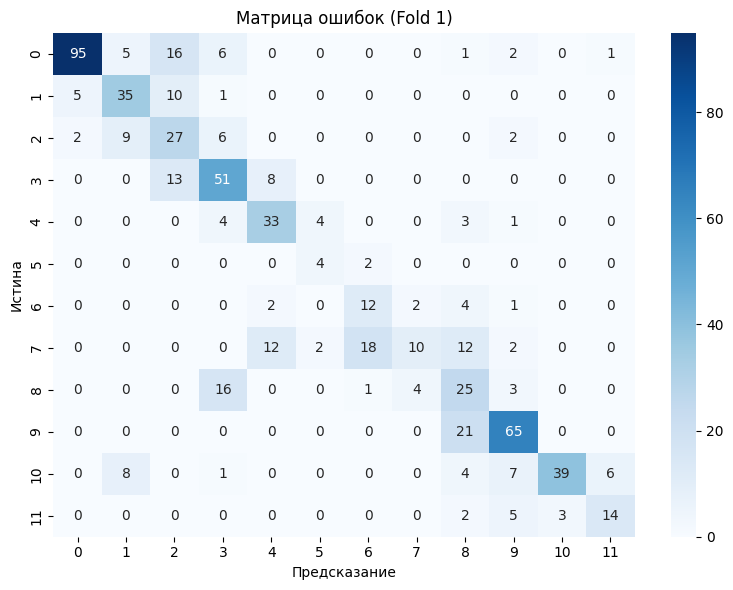

Fold 2
  Train wells: ['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'E1']
  Val wells:   ['C2', 'C7', 'D1']
  Train: 2370 проб, Val: 658 проб
F1 macro (train): 0.9995
F1 macro (val):   0.6654
Gap (train-val):  0.3341

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.9417    0.8661    0.9023       112
           1     0.4000    0.7143    0.5128        14
           2     0.5714    0.6087    0.5895        46
           3     0.8611    0.8052    0.8322        77
           4     0.6250    0.8824    0.7317        68
           5     0.5500    0.2444    0.3385        45
           6     0.4118    0.2593    0.3182        27
           7     0.4524    0.6129    0.5205        31
           8     0.6458    0.7294    0.6851        85
           9     0.8571    0.7568    0.8038       111
          10     0.9412    0.7273    0.8205        22
          11     0.8696    1.0000    0.9302        20

    accuracy                    

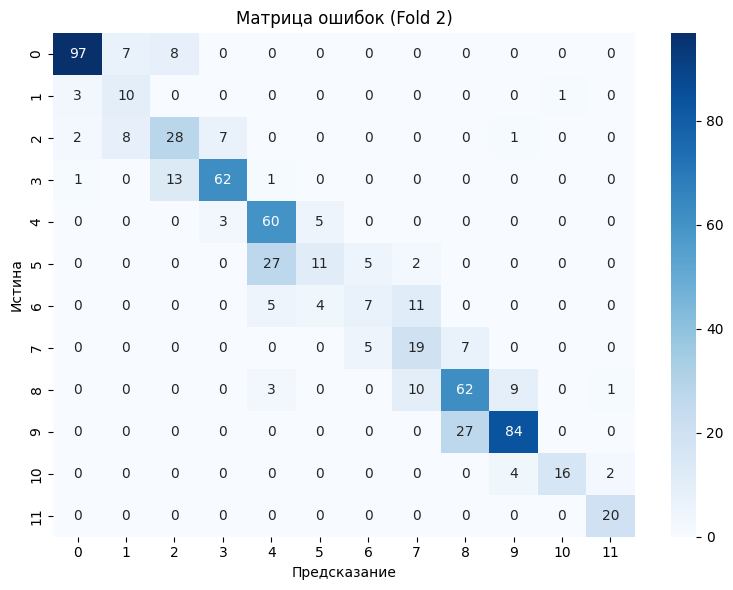

Fold 3
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A3', 'C1', 'C5']
  Train: 2429 проб, Val: 599 проб
F1 macro (train): 0.9996
F1 macro (val):   0.6910
Gap (train-val):  0.3086

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.9609    0.9840    0.9723       125
           1     0.8667    0.7222    0.7879        36
           2     0.8077    0.6562    0.7241        32
           3     0.7143    0.8333    0.7692        30
           4     0.6250    0.5556    0.5882        36
           5     0.5455    0.3333    0.4138        36
           6     0.3333    0.1818    0.2353        33
           7     0.3714    0.3250    0.3467        40
           8     0.6271    0.8409    0.7184        88
           9     0.8090    0.9231    0.8623        78
          10     0.9318    0.9111    0.9213        45
          11     0.9091    1.0000    0.9524        20

    accuracy                    

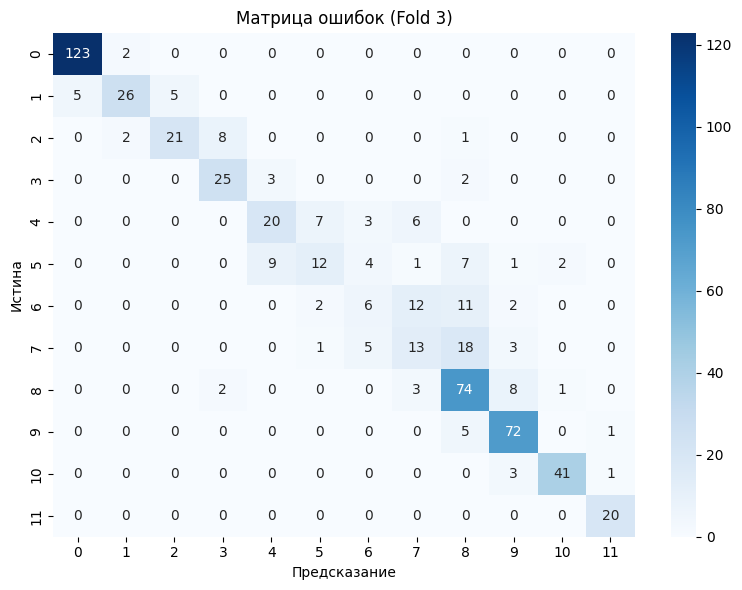

Fold 4
  Train wells: ['A1', 'A3', 'A4', 'C1', 'C2', 'C4', 'C5', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A2', 'B1', 'C3']
  Train: 2465 проб, Val: 563 проб
F1 macro (train): 0.9998
F1 macro (val):   0.6664
Gap (train-val):  0.3334

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.9206    1.0000    0.9587        58
           1     1.0000    0.3846    0.5556        39
           2     0.4333    0.7429    0.5474        35
           3     0.7400    0.7115    0.7255        52
           4     0.8723    0.7321    0.7961        56
           5     0.6667    0.5000    0.5714        24
           6     0.4889    0.7857    0.6027        28
           7     0.5833    0.1591    0.2500        44
           8     0.4912    0.4444    0.4667        63
           9     0.6408    0.9041    0.7500        73
          10     0.8333    0.9821    0.9016        56
          11     1.0000    0.7714    0.8710        35

    accuracy                    

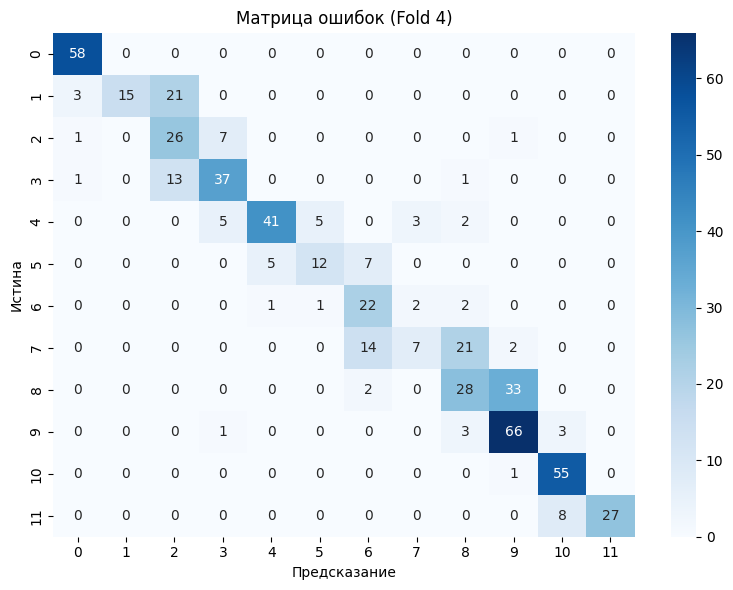

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'B1', 'C1', 'C2', 'C3', 'C5', 'C7', 'D1', 'E1']
  Val wells:   ['A4', 'C4', 'C6']
  Train: 2467 проб, Val: 561 проб
F1 macro (train): 0.9982
F1 macro (val):   0.5827
Gap (train-val):  0.4154

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.6136    1.0000    0.7606        27
           1     0.6250    0.3125    0.4167        16
           2     0.6087    0.6087    0.6087        23
           3     0.7949    0.8611    0.8267        36
           4     0.5111    0.8214    0.6301        28
           5     0.2727    0.1364    0.1818        22
           6     0.6667    0.7273    0.6957        22
           7     0.2414    0.3043    0.2692        23
           8     0.5811    0.5375    0.5584        80
           9     0.7143    0.7851    0.7480       121
          10     0.6458    0.7848    0.7086        79
          11     1.0000    0.4167    0.5882        84

    accuracy                    

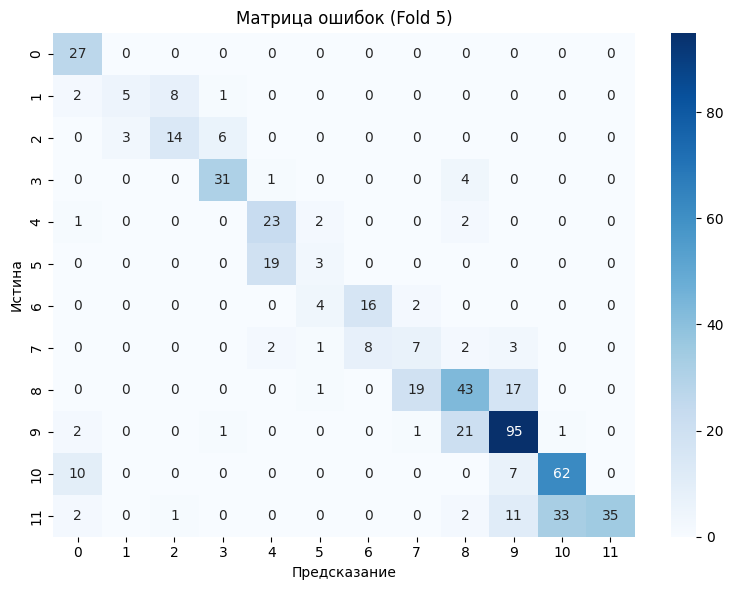

Результаты кросс-валидации
  Fold 1: F1_macro = 0.5839
  Fold 2: F1_macro = 0.6654
  Fold 3: F1_macro = 0.6910
  Fold 4: F1_macro = 0.6664
  Fold 5: F1_macro = 0.5827

  Средний F1 macro: 0.6379 ± 0.0455

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.9091    0.8929    0.9009       448
           1     0.6741    0.5833    0.6254       156
           2     0.5179    0.6374    0.5714       182
           3     0.7331    0.7715    0.7518       267
           4     0.6436    0.7597    0.6969       233
           5     0.5185    0.3158    0.3925       133
           6     0.4599    0.4809    0.4701       131
           7     0.4179    0.2887    0.3415       194
           8     0.5564    0.6356    0.5934       365
           9     0.7476    0.8145    0.7796       469
          10     0.8038    0.7978    0.8008       267
          11     0.9062    0.6339    0.7460       183

    accuracy                         0.6915      

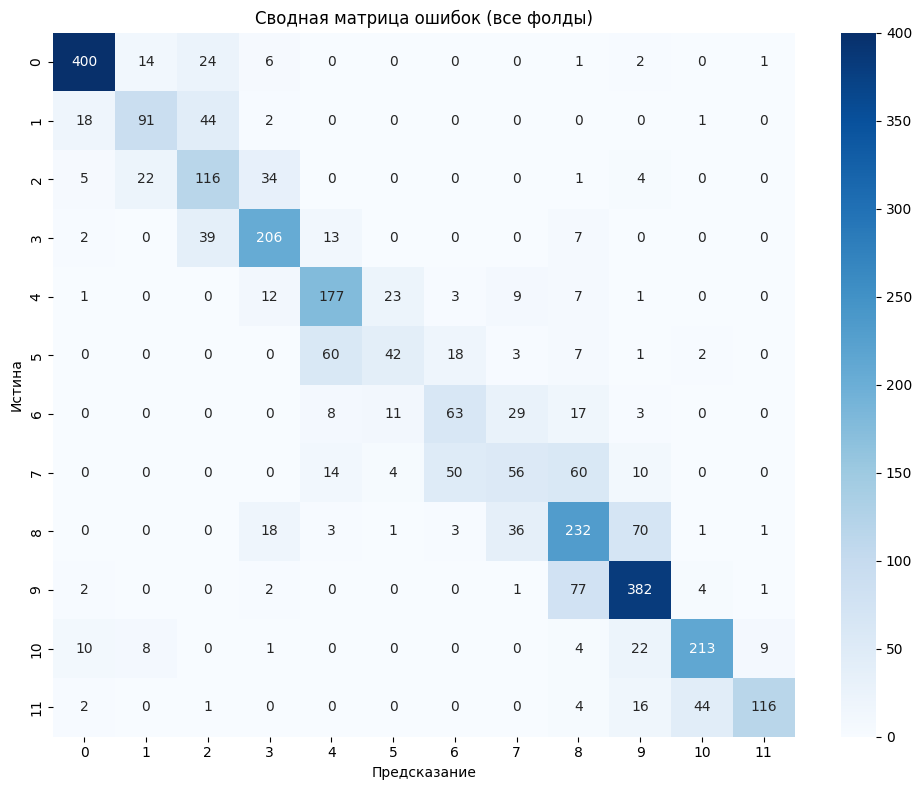

/tmp/ipykernel_313437/1782897511.py:133: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exc

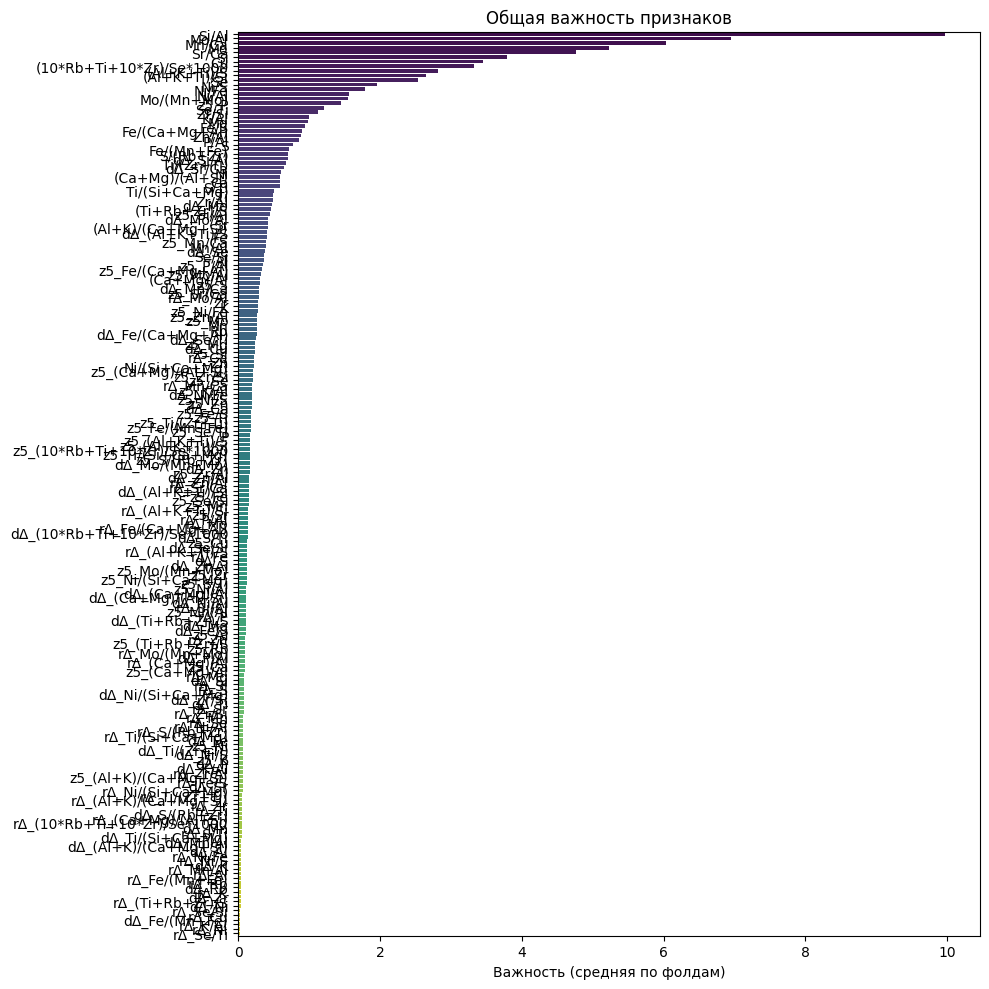

In [54]:
X = df[features]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42,
    'task_type': 'GPU',
    'devices': '0'
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []

# Накопители для SHAP и важности
shap_all = []           # список массивов (n_val_samples, n_classes, n_features)
importance_all = []      # список массивов (n_features,) — важность от каждой модели

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    # shap_values: (n_samples, n_classes, n_features + 1)
    shap_per_class = shap_values[:, :, :-1]  # (n_samples, n_classes, n_features)
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Сохранение в CSV
# results_df = pd.concat(results_df_list, ignore_index=True)
# results_df.to_csv('Result/classification_results_CatBoost_fixed_elements_ratios.csv', index=False)

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")
print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(features, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()

In [56]:
# Исправленная версия
def permutation_importance_custom(model, X_val, y_val, 
                                   features_list, n_repeats=3, 
                                   random_state=42):
    rng = np.random.RandomState(random_state)
    baseline = f1_score(y_val, model.predict(X_val), average='macro')
    print(f"Baseline F1 macro: {baseline:.4f}\n")
    
    results = []
    for i, col in enumerate(features_list):
        scores = []
        for _ in range(n_repeats):
            X_permuted = X_val.copy()
            X_permuted.iloc[:, i] = rng.permutation(X_permuted.iloc[:, i].values)
            score = f1_score(y_val, model.predict(X_permuted), average='macro')
            scores.append(score)
        drop = baseline - np.mean(scores)
        results.append((col, drop, np.std(scores)))
        if (i + 1) % 10 == 0:
            print(f"Processed {i+1}/{len(features_list)}")
    
    results.sort(key=lambda x: x[1], reverse=True)
    return results

perm_results = permutation_importance_custom(
    model, X_vl, y_vl, 
    features_list=X_vl.columns.tolist(),
    n_repeats=3
)

print(f"\n{'Признак':<45} {'Drop F1':>10} {'Std':>8}")
print("-" * 65)
for col, drop, std in perm_results[:30]:
    print(f"{col:<45} {drop:>10.4f} {std:>8.4f}")

# Признаки с drop <= 0 — можно удалить
useless = [(col, drop) for col, drop, std in perm_results if drop <= 0]
print(f"\nБесполезных признаков (drop <= 0): {len(useless)}")


Baseline F1 macro: 0.5827

Processed 10/196
Processed 20/196
Processed 30/196
Processed 40/196
Processed 50/196
Processed 60/196
Processed 70/196
Processed 80/196
Processed 90/196
Processed 100/196
Processed 110/196
Processed 120/196
Processed 130/196
Processed 140/196
Processed 150/196
Processed 160/196
Processed 170/196
Processed 180/196
Processed 190/196

Признак                                          Drop F1      Std
-----------------------------------------------------------------
Si/Al                                             0.0299   0.0023
Sr/Ca                                             0.0284   0.0101
Mo/Al                                             0.0225   0.0055
z5_P                                              0.0202   0.0015
Fe/(Ca+Mg+Al)                                     0.0172   0.0020
Mn/Ca                                             0.0156   0.0013
Si                                                0.0133   0.0028
Mo                                           

**Отбор признаков с permutation_importance**

Fold 1
  Train wells: ['A2', 'A3', 'A4', 'B1', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'D1']
  Val wells:   ['A1', 'E1']
  Train: 2381 проб, Val: 647 проб
F1 macro (train): 0.9989
F1 macro (val):   0.5805
Gap (train-val):  0.4184

Classification Report (Fold 1)
              precision    recall  f1-score   support

           0     0.9375    0.7143    0.8108       126
           1     0.5902    0.7059    0.6429        51
           2     0.4118    0.6087    0.4912        46
           3     0.5667    0.7083    0.6296        72
           4     0.5818    0.7111    0.6400        45
           5     0.4000    0.6667    0.5000         6
           6     0.3438    0.5238    0.4151        21
           7     0.5909    0.2321    0.3333        56
           8     0.3607    0.4490    0.4000        49
           9     0.7500    0.7674    0.7586        86
          10     0.9070    0.6000    0.7222        65
          11     0.6667    0.5833    0.6222        24

    accuracy                    

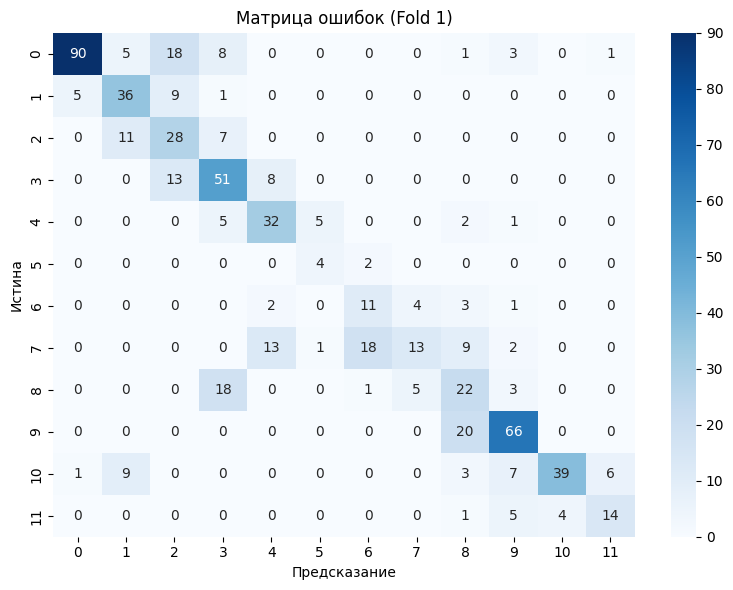

Fold 2
  Train wells: ['A1', 'A2', 'A3', 'A4', 'B1', 'C1', 'C3', 'C4', 'C5', 'C6', 'E1']
  Val wells:   ['C2', 'C7', 'D1']
  Train: 2370 проб, Val: 658 проб
F1 macro (train): 0.9995
F1 macro (val):   0.6654
Gap (train-val):  0.3341

Classification Report (Fold 2)
              precision    recall  f1-score   support

           0     0.9417    0.8661    0.9023       112
           1     0.4000    0.7143    0.5128        14
           2     0.5714    0.6087    0.5895        46
           3     0.8611    0.8052    0.8322        77
           4     0.6250    0.8824    0.7317        68
           5     0.5500    0.2444    0.3385        45
           6     0.4118    0.2593    0.3182        27
           7     0.4524    0.6129    0.5205        31
           8     0.6458    0.7294    0.6851        85
           9     0.8571    0.7568    0.8038       111
          10     0.9412    0.7273    0.8205        22
          11     0.8696    1.0000    0.9302        20

    accuracy                    

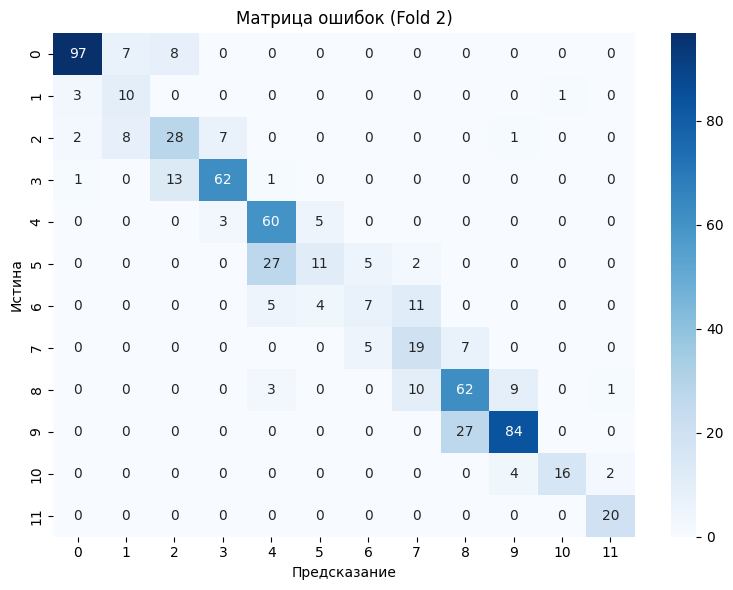

Fold 3
  Train wells: ['A1', 'A2', 'A4', 'B1', 'C2', 'C3', 'C4', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A3', 'C1', 'C5']
  Train: 2429 проб, Val: 599 проб
F1 macro (train): 0.9996
F1 macro (val):   0.6910
Gap (train-val):  0.3086

Classification Report (Fold 3)
              precision    recall  f1-score   support

           0     0.9609    0.9840    0.9723       125
           1     0.8667    0.7222    0.7879        36
           2     0.8077    0.6562    0.7241        32
           3     0.7143    0.8333    0.7692        30
           4     0.6250    0.5556    0.5882        36
           5     0.5455    0.3333    0.4138        36
           6     0.3333    0.1818    0.2353        33
           7     0.3714    0.3250    0.3467        40
           8     0.6271    0.8409    0.7184        88
           9     0.8090    0.9231    0.8623        78
          10     0.9318    0.9111    0.9213        45
          11     0.9091    1.0000    0.9524        20

    accuracy                    

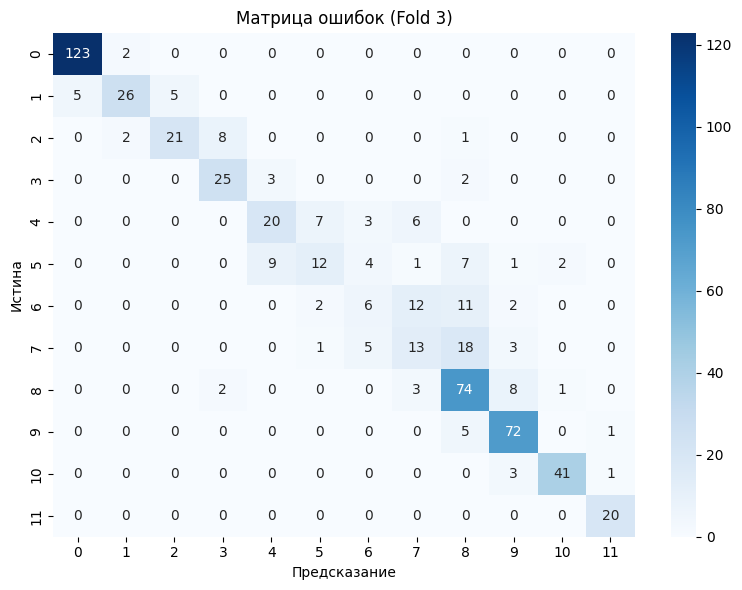

Fold 4
  Train wells: ['A1', 'A3', 'A4', 'C1', 'C2', 'C4', 'C5', 'C6', 'C7', 'D1', 'E1']
  Val wells:   ['A2', 'B1', 'C3']
  Train: 2465 проб, Val: 563 проб
F1 macro (train): 0.9998
F1 macro (val):   0.6664
Gap (train-val):  0.3334

Classification Report (Fold 4)
              precision    recall  f1-score   support

           0     0.9206    1.0000    0.9587        58
           1     1.0000    0.3846    0.5556        39
           2     0.4333    0.7429    0.5474        35
           3     0.7400    0.7115    0.7255        52
           4     0.8723    0.7321    0.7961        56
           5     0.6667    0.5000    0.5714        24
           6     0.4889    0.7857    0.6027        28
           7     0.5833    0.1591    0.2500        44
           8     0.4912    0.4444    0.4667        63
           9     0.6408    0.9041    0.7500        73
          10     0.8333    0.9821    0.9016        56
          11     1.0000    0.7714    0.8710        35

    accuracy                    

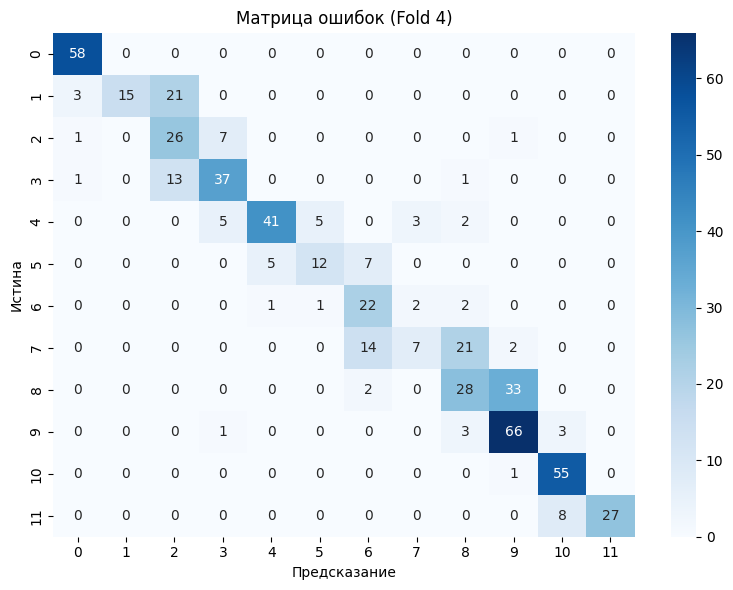

Fold 5
  Train wells: ['A1', 'A2', 'A3', 'B1', 'C1', 'C2', 'C3', 'C5', 'C7', 'D1', 'E1']
  Val wells:   ['A4', 'C4', 'C6']
  Train: 2467 проб, Val: 561 проб
F1 macro (train): 0.9982
F1 macro (val):   0.5827
Gap (train-val):  0.4154

Classification Report (Fold 5)
              precision    recall  f1-score   support

           0     0.6136    1.0000    0.7606        27
           1     0.6250    0.3125    0.4167        16
           2     0.6087    0.6087    0.6087        23
           3     0.7949    0.8611    0.8267        36
           4     0.5111    0.8214    0.6301        28
           5     0.2727    0.1364    0.1818        22
           6     0.6667    0.7273    0.6957        22
           7     0.2414    0.3043    0.2692        23
           8     0.5811    0.5375    0.5584        80
           9     0.7143    0.7851    0.7480       121
          10     0.6458    0.7848    0.7086        79
          11     1.0000    0.4167    0.5882        84

    accuracy                    

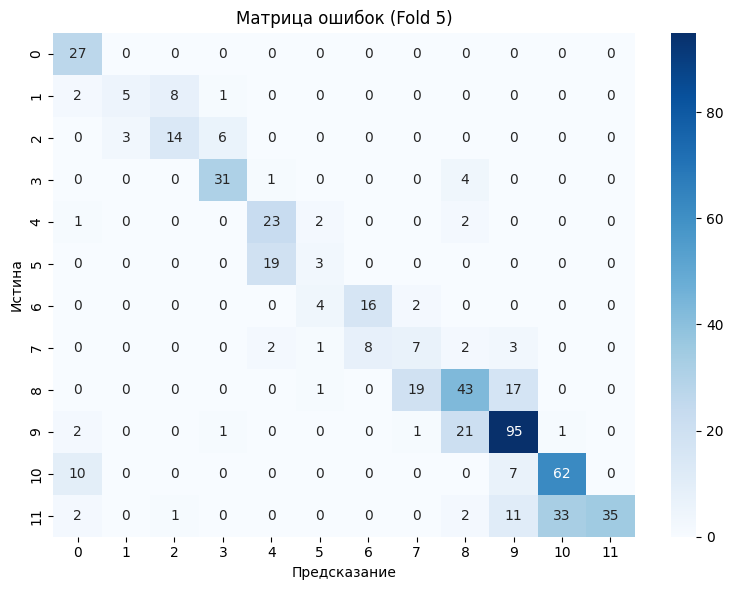

Результаты кросс-валидации
  Fold 1: F1_macro = 0.5805
  Fold 2: F1_macro = 0.6654
  Fold 3: F1_macro = 0.6910
  Fold 4: F1_macro = 0.6664
  Fold 5: F1_macro = 0.5827

  Средний F1 macro: 0.6372 ± 0.0463

Сводный Classification Report (все фолды)
              precision    recall  f1-score   support

           0     0.9101    0.8817    0.8957       448
           1     0.6619    0.5897    0.6237       156
           2     0.5177    0.6429    0.5735       182
           3     0.7203    0.7715    0.7450       267
           4     0.6400    0.7554    0.6929       233
           5     0.5185    0.3158    0.3925       133
           6     0.4559    0.4733    0.4644       131
           7     0.4214    0.3041    0.3533       194
           8     0.5640    0.6274    0.5940       365
           9     0.7495    0.8166    0.7816       469
          10     0.8008    0.7978    0.7992       267
          11     0.9062    0.6339    0.7460       183

    accuracy                         0.6902      

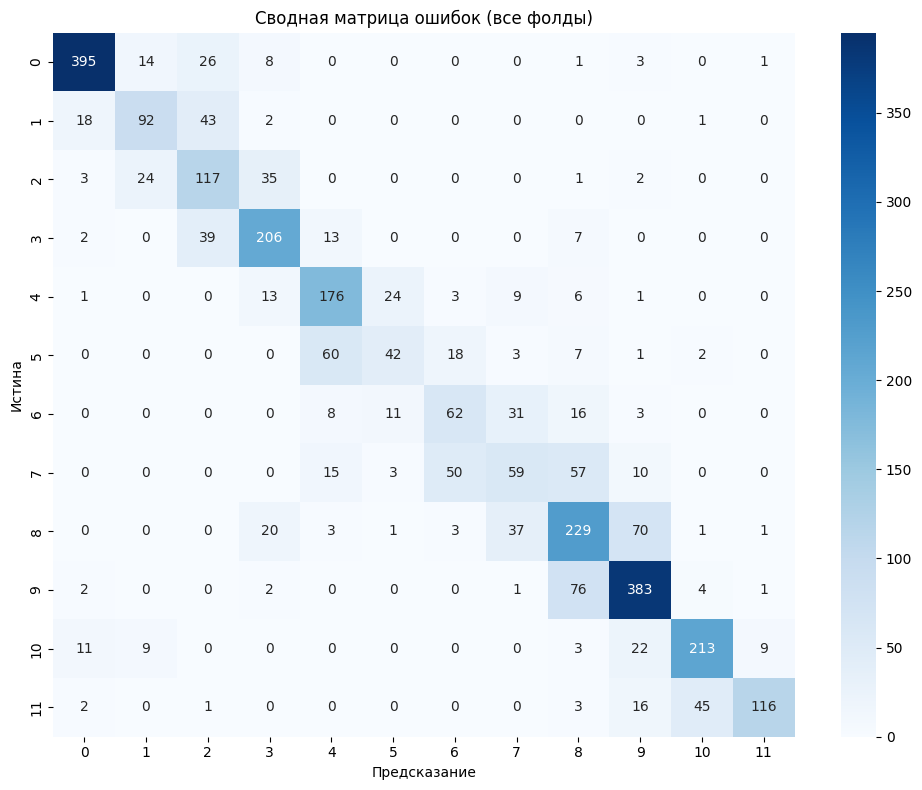

/tmp/ipykernel_313437/678660341.py:147: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to excl

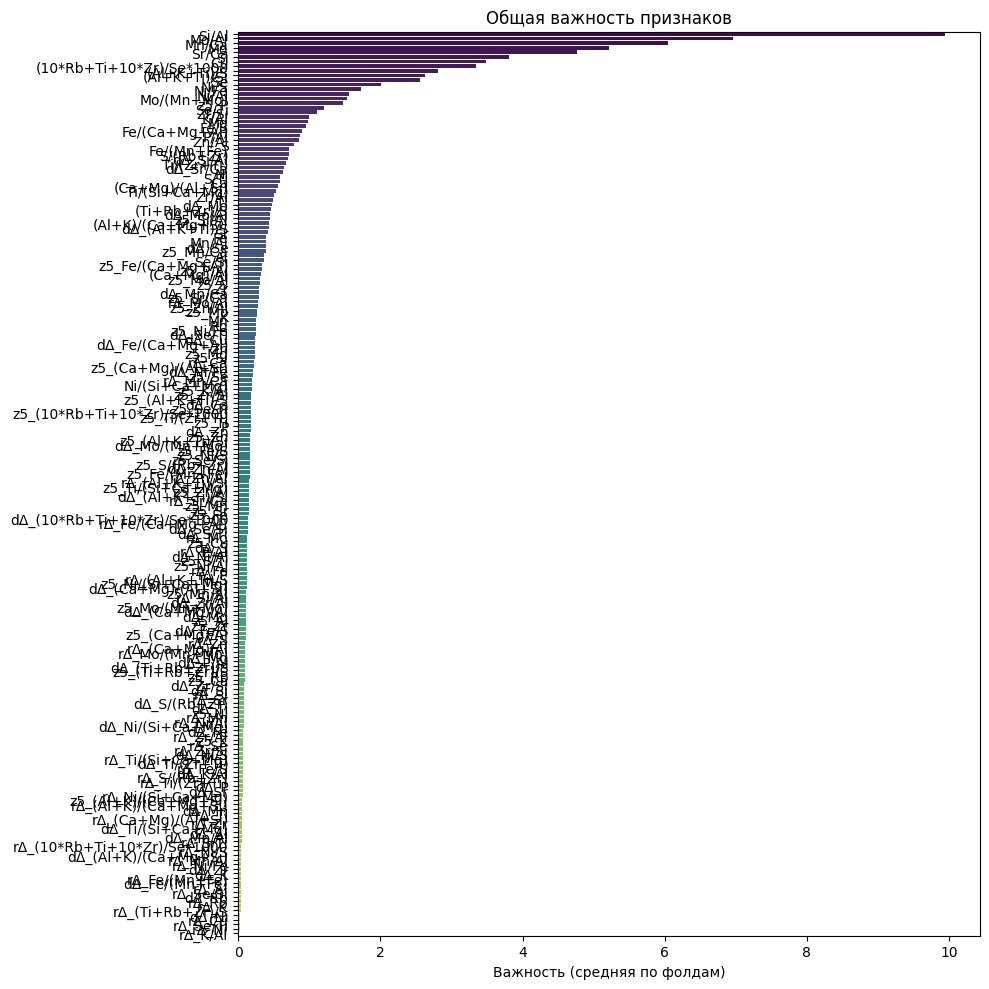


Permutation Importance (агрегировано по 5 фолдам)
Полезных на >=3 фолдах: 118 из 196

Топ-30:
                 feature  n_folds_useful  mean_drop  std_drop
                   Si/Al               5   0.043377  0.015417
                      Cu               5   0.025003  0.015580
                   Sr/Ca               5   0.023583  0.011505
                      Mo               5   0.020240  0.018197
                   Mn/Ca               5   0.019882  0.016755
                      Si               5   0.017548  0.006881
                dΔ_Sr/Ca               5   0.007878  0.001301
                    Ni/S               5   0.006204  0.001238
                z5_Si/Al               5   0.002972  0.001558
                    dΔ_S               5   0.002876  0.001884
                dΔ_Si/Al               5   0.002333  0.001351
         z5_(Al+K+Ti)/Si               5   0.001330  0.000798
           dΔ_Ti/(Zr+Ti)               5   0.000341  0.000139
                   Mo/Al             

/tmp/ipykernel_313437/678660341.py:176: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='mean_drop', y='feature', data=top30, palette='rocket')
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/seaborn/categorical.py:1273: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings

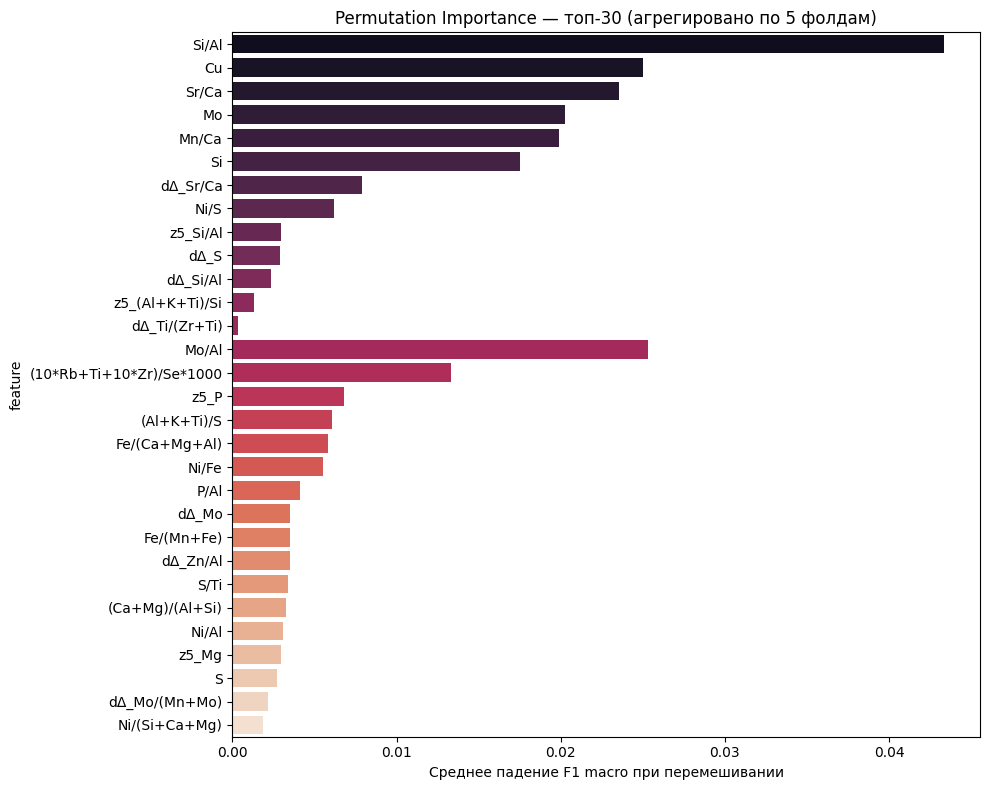


Стабильных признаков: 118
['Si/Al', 'Cu', 'Sr/Ca', 'Mo', 'Mn/Ca', 'Si', 'dΔ_Sr/Ca', 'Ni/S', 'z5_Si/Al', 'dΔ_S', 'dΔ_Si/Al', 'z5_(Al+K+Ti)/Si', 'dΔ_Ti/(Zr+Ti)', 'Mo/Al', '(10*Rb+Ti+10*Zr)/Se*1000', 'z5_P', '(Al+K+Ti)/S', 'Fe/(Ca+Mg+Al)', 'Ni/Fe', 'P/Al', 'dΔ_Mo', 'Fe/(Mn+Fe)', 'dΔ_Zn/Al', 'S/Ti', '(Ca+Mg)/(Al+Si)', 'Ni/Al', 'z5_Mg', 'S', 'dΔ_Mo/(Mn+Mo)', 'Ni/(Si+Ca+Mg)', 'rΔ_Sr/Ca', 'dΔ_Zn', 'rΔ_S/(Rb+Zr)', 'rΔ_(Al+K+Ti)/Si', 'dΔ_Cu', 'dΔ_S/Ti', 'rΔ_(Ca+Mg)/(Al+Si)', 'Mn', 'rΔ_Mn', 'z5_S', 'z5_Fe/(Ca+Mg+Al)', 'rΔ_Si', 'z5_Mo/(Mn+Mo)', 'z5_Ti/(Zr+Ti)', 'z5_Ni/S', 'dΔ_Zr', 'dΔ_Fe', 'rΔ_P', 'dΔ_Zr/Al', 'Fe', 'Se', 'Mo/(Mn+Mo)', 'Fe/S', 'z5_Zn', 'z5_Cu', 'z5_(Al+K)/(Ca+Mg+Si)', 'dΔ_Mn/Ca', 'rΔ_Mo', 'Rb', 'dΔ_Mo/Al', 'rΔ_S/Ti', 'Ca', 'Ni', 'rΔ_Mo/Al', 'z5_Ni/Fe', 'K/Al', 'S/(Rb+Zr)', 'rΔ_Mn/Ca', 'z5_Se/Si', 'dΔ_Se/Si', 'rΔ_Ti/(Zr+Ti)', 'rΔ_Ca', 'rΔ_Mg', '(Ti+Rb+Zr)/S', 'Ti/(Si+Ca+Mg)', 'dΔ_Ti', 'rΔ_Ni/Al', 'Mg', 'Se/Ti', 'dΔ_Ti/(Si+Ca+Mg)', 'dΔ_Mn', 'dΔ_Mn/Al', 'z5_Rb', 'z5_Ni/(Si+Ca+Mg)', 

In [57]:
from sklearn.metrics import f1_score
import numpy as np

X = df[features]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42,
    'task_type': 'GPU',
    'devices': '0'
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
results_df_list = []

# Накопители для SHAP и важности
shap_all = []
importance_all = []

# Накопитель для permutation importance
perm_all = []  # список dict: {feature: drop_f1} для каждого фолда

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    groups_tr = groups.iloc[train_idx]

    train_wells = sorted(groups_tr.unique())
    val_wells = sorted(groups.iloc[val_idx].unique())

    print(f"Fold {fold}")
    print(f"  Train wells: {train_wells}")
    print(f"  Val wells:   {val_wells}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    # Предсказания модели
    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()
    proba_val = model.predict_proba(X_vl)
    proba_train = model.predict_proba(X_tr)

    # Метрики
    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"F1 macro (train): {f1_train:.4f}")
    print(f"F1 macro (val):   {f1_val:.4f}")
    print(f"Gap (train-val):  {gap:.4f}")

    print(f"\nClassification Report (Fold {fold})")
    print(classification_report(y_vl, y_pred, digits=4))

    # SHAP для val
    pool_val = Pool(X_vl, y_vl)
    shap_values = model.get_feature_importance(
        pool_val,
        type='ShapValues'
    )
    shap_per_class = shap_values[:, :, :-1]
    shap_all.append(shap_per_class)

    # Общая важность признаков
    importance_all.append(model.get_feature_importance())

    # Permutation importance для текущего фолда
    rng = np.random.RandomState(42)
    perm_results = {}
    for i, col in enumerate(X_vl.columns):
        scores = []
        for _ in range(3):
            X_perm = X_vl.copy()
            X_perm.iloc[:, i] = rng.permutation(X_perm.iloc[:, i].values)
            scores.append(f1_score(y_vl, model.predict(X_perm), average='macro'))
        perm_results[col] = f1_val - np.mean(scores)
    perm_all.append(perm_results)
    print(f"  Permutation importance посчитан для {len(perm_results)} признаков")

    # Сбор строк для CSV
    df_vl = X_vl.copy()
    df_vl['Well'] = df.loc[X_vl.index, 'Well'].values
    df_vl['Sample'] = df.loc[X_vl.index, 'Sample'].values
    df_vl['Depth'] = df.loc[X_vl.index, 'Depth'].values
    df_vl['Stratigraphy'] = df.loc[X_vl.index, 'Stratigraphy'].values
    df_vl['Strat'] = y_vl.values
    df_vl['Pred_Strat'] = y_pred
    for c in range(12):
        df_vl[f'Prob_{c}'] = proba_val[:, c]
    df_vl['Fold'] = fold
    df_vl['Split'] = 'val'
    df_vl['Correct'] = (y_vl.values == y_pred).astype(int)

    results_df_list.append(df_vl)

    plt.figure(figsize=(8, 6))
    cm = confusion_matrix(y_vl, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(12), yticklabels=range(12))
    plt.xlabel('Предсказание')
    plt.ylabel('Истина')
    plt.title(f'Матрица ошибок (Fold {fold})')
    plt.tight_layout()
    plt.show()

# Итог
print(f"Результаты кросс-валидации")

for i, s in enumerate(fold_scores, 1):
    print(f"  Fold {i}: F1_macro = {s:.4f}")
print(f"\n  Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")

print(f"\nСводный Classification Report (все фолды)")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Сводная матрица ошибок (все фолды)')
plt.tight_layout()
plt.show()

# Общая важность признаков (усреднённая по фолдам)
importance_mean = np.mean(importance_all, axis=0)
feat_imp = sorted(zip(features, importance_mean), key=lambda x: x[1], reverse=True)

plt.figure(figsize=(10, 10))
sns.barplot(x=[f[1] for f in feat_imp], y=[f[0] for f in feat_imp], palette='viridis')
plt.xlabel('Важность (средняя по фолдам)')
plt.title('Общая важность признаков')
plt.tight_layout()
plt.show()

# ── Permutation Importance: агрегация по фолдам ──
n_folds = len(perm_all)
min_folds_useful = n_folds // 2 + 1  # больше половины фолдов

perm_summary = pd.DataFrame({
    'feature': features,
    'n_folds_useful': [sum(1 for res in perm_all if res[col] > 0) for col in features],
    'mean_drop': [np.mean([res[col] for res in perm_all]) for col in features],
    'std_drop': [np.std([res[col] for res in perm_all]) for col in features]
}).sort_values(['n_folds_useful', 'mean_drop'], ascending=[False, False])

print(f"\nPermutation Importance (агрегировано по {n_folds} фолдам)")
print(f"Полезных на >={min_folds_useful} фолдах: "
      f"{(perm_summary['n_folds_useful'] >= min_folds_useful).sum()} из {len(features)}")
print(f"\nТоп-30:")
print(perm_summary.head(30).to_string(index=False))

print(f"\nБесполезные на всех фолдах (n_folds_useful=0): "
      f"{(perm_summary['n_folds_useful'] == 0).sum()}")

# Топ-30 permutation importance
plt.figure(figsize=(10, 8))
top30 = perm_summary.head(30)
sns.barplot(x='mean_drop', y='feature', data=top30, palette='rocket')
plt.xlabel('Среднее падение F1 macro при перемешивании')
plt.title(f'Permutation Importance — топ-30 (агрегировано по {n_folds} фолдам)')
plt.tight_layout()
plt.show()

# Список стабильных признаков
stable_features = perm_summary[perm_summary['n_folds_useful'] >= min_folds_useful]['feature'].tolist()
print(f"\nСтабильных признаков: {len(stable_features)}")
print(stable_features)


**Жесткий отбор признаков n_folds_useful >= 4**

Признаков до отбора: 196
Признаков после жёсткого отбора (>= 4 фолдов): 50
Fold 1
  Train: 2381 проб, Val: 647 проб
  F1 macro (train): 0.9989
  F1 macro (val):   0.5717
  Gap:              0.4272
Fold 2
  Train: 2370 проб, Val: 658 проб
  F1 macro (train): 0.9989
  F1 macro (val):   0.6686
  Gap:              0.3304
Fold 3
  Train: 2429 проб, Val: 599 проб
  F1 macro (train): 0.9990
  F1 macro (val):   0.6797
  Gap:              0.3193
Fold 4
  Train: 2465 проб, Val: 563 проб
  F1 macro (train): 0.9998
  F1 macro (val):   0.6577
  Gap:              0.3421
Fold 5
  Train: 2467 проб, Val: 561 проб
  F1 macro (train): 0.9977
  F1 macro (val):   0.5859
  Gap:              0.4118

Результаты жёсткого отбора (>= 4 фолдов, 50 признаков)
  Средний F1 macro: 0.6327 ± 0.0448

Сводный Classification Report:
              precision    recall  f1-score   support

           0     0.9065    0.8661    0.8858       448
           1     0.6577    0.6282    0.6426       156
           2     0.5022    0

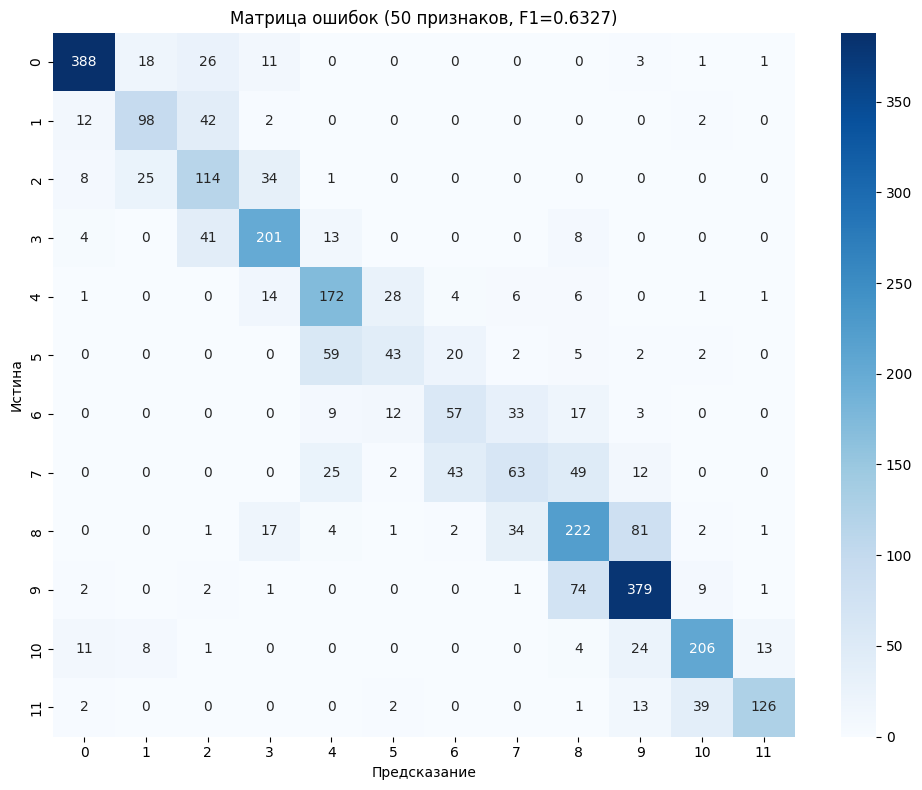

In [60]:
# Жёсткий отбор: только n_folds_useful >= 4
strict_features = perm_summary[perm_summary['n_folds_useful'] >= 4]['feature'].tolist()

print(f"Признаков до отбора: {len(features)}")
print(f"Признаков после жёсткого отбора (>= 4 фолдов): {len(strict_features)}")

# Перезапускаем кросс-валидацию на отобранных признаках
X = df[strict_features]
y = df['Strat']
groups = df['Well']

fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42,
    'task_type': 'GPU',
    'devices': '0'
}

gkf = GroupKFold(n_splits=5)

fold_scores_strict = []
all_preds_strict = []
all_true_strict = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]

    print(f"Fold {fold}")
    print(f"  Train: {len(X_tr)} проб, Val: {len(X_vl)} проб")

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)

    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()

    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores_strict.append(f1_val)
    all_preds_strict.extend(y_pred)
    all_true_strict.extend(y_vl.values)

    print(f"  F1 macro (train): {f1_train:.4f}")
    print(f"  F1 macro (val):   {f1_val:.4f}")
    print(f"  Gap:              {gap:.4f}")

print(f"\n{'='*50}")
print(f"Результаты жёсткого отбора (>= 4 фолдов, {len(strict_features)} признаков)")
print(f"  Средний F1 macro: {np.mean(fold_scores_strict):.4f} ± {np.std(fold_scores_strict):.4f}")
print(f"\nСводный Classification Report:")
print(classification_report(all_true_strict, all_preds_strict, digits=4))

plt.figure(figsize=(10, 8))
cm_strict = confusion_matrix(all_true_strict, all_preds_strict)
sns.heatmap(cm_strict, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title(f'Матрица ошибок ({len(strict_features)} признаков, F1={np.mean(fold_scores_strict):.4f})')
plt.tight_layout()
plt.show()


**Подбор новых парметров**

Fold 1
  F1 (train): 0.7752
  F1 (val):   0.5164
  Gap:        0.2588
Fold 2
  F1 (train): 0.7795
  F1 (val):   0.6119
  Gap:        0.1676
Fold 3
  F1 (train): 0.7790
  F1 (val):   0.5940
  Gap:        0.1850
Fold 4
  F1 (train): 0.7937
  F1 (val):   0.6096
  Gap:        0.1841
Fold 5
  F1 (train): 0.7923
  F1 (val):   0.5388
  Gap:        0.2536

Средний F1 macro: 0.5741 ± 0.0391
Средний gap:       0.2098

Classification Report:
              precision    recall  f1-score   support

           0     0.8497    0.8326    0.8410       448
           1     0.5938    0.6090    0.6013       156
           2     0.4526    0.4725    0.4624       182
           3     0.6771    0.7303    0.7027       267
           4     0.5704    0.7124    0.6336       233
           5     0.3235    0.1654    0.2189       133
           6     0.4583    0.4198    0.4382       131
           7     0.3782    0.2320    0.2875       194
           8     0.4839    0.5753    0.5257       365
           9     0.6812 

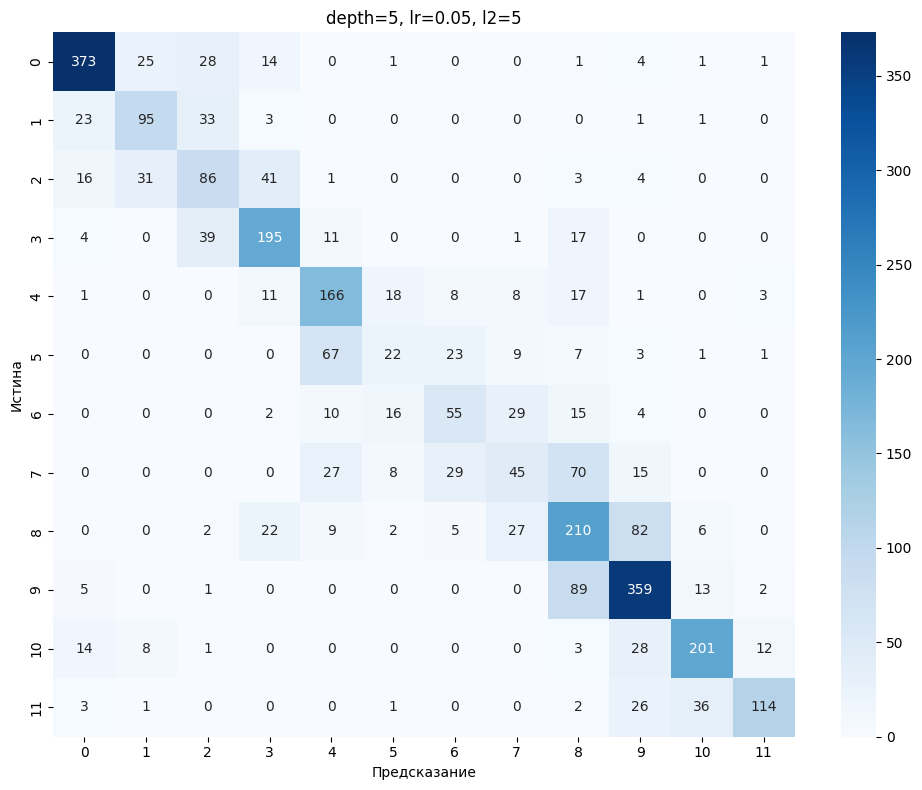

In [26]:
fixed_params = {
    'depth': 5,
    'iterations': 800,
    'learning_rate': 0.01,
    'l2_leaf_reg': 5,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42,
    'early_stopping_rounds': 50,
    'task_type': 'GPU',
    'devices': '0'
}

gkf = GroupKFold(n_splits=5)

fold_scores = []
all_preds = []
all_true = []
fold_gaps = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]

    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr, eval_set=(X_vl, y_vl), use_best_model=True)

    y_pred = model.predict(X_vl).ravel()
    y_train_pred = model.predict(X_tr).ravel()

    f1_val = f1_score(y_vl, y_pred, average='macro')
    f1_train = f1_score(y_tr, y_train_pred, average='macro')
    gap = f1_train - f1_val

    fold_scores.append(f1_val)
    fold_gaps.append(gap)
    all_preds.extend(y_pred)
    all_true.extend(y_vl.values)

    print(f"Fold {fold}")
    print(f"  F1 (train): {f1_train:.4f}")
    print(f"  F1 (val):   {f1_val:.4f}")
    print(f"  Gap:        {gap:.4f}")

print(f"\n{'='*50}")
print(f"Средний F1 macro: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}")
print(f"Средний gap:       {np.mean(fold_gaps):.4f}")

print(f"\nClassification Report:")
print(classification_report(all_true, all_preds, digits=4))

plt.figure(figsize=(10, 8))
cm_all = confusion_matrix(all_true, all_preds)
sns.heatmap(cm_all, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(12), yticklabels=range(12))
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title(f'depth=5, lr=0.05, l2=5')
plt.tight_layout()
plt.show()



**gap 0.35 при GroupKFold -это не классическое переобучение, и борьба с ним не помогает. Обычное переобучение когда модель запоминает train и вал F1 растёт при регуляризации. Здесь регуляризация gap уменьшает, но val F1 не растёт. Значит, проблема не в том, что модель слишком сложная, а в том, что скважины отличаются друг от друга по геохимии, модель учит паттерны одной скважины, а другая живёт по своим правилам.**
**Во всех вариантах val F1 падает вместе с gap.**

**Viterbi-постобработка**

In [59]:
from collections import Counter

X = df[strict_features]
y = df['Strat']
groups = df['Well']

# 1. Оценка transition matrix по тренировочным данным
def build_transition_matrix(y_train, wells_train, n_classes=12):
    """Считаем переходы между классами по глубине внутри каждой скважины"""
    trans = np.ones((n_classes, n_classes))  # Laplace smoothing
    for well in wells_train.unique():
        mask = wells_train == well
        labels = y_train[mask].values
        for i in range(len(labels) - 1):
            trans[labels[i], labels[i+1]] += 1
    # Нормализуем строки
    trans = trans / trans.sum(axis=1, keepdims=True)
    return trans

# 2. Оценка начальных распределений
def build_start_probs(y_train, wells_train, n_classes=12):
    """Какой класс чаще всего встречается первым в скважине"""
    start = np.ones(n_classes)  # Laplace
    for well in wells_train.unique():
        mask = wells_train == well
        labels = y_train[mask].values
        start[labels[0]] += 1
    return start / start.sum()

# 3. Viterbi-декодирование для одной скважины
def viterbi_decode(probs_well, trans_mat, start_probs):
    """
    probs_well: (n_samples, n_classes) — вероятности от CatBoost
    Возвращает наиболее правдоподобную последовательность классов
    """
    n_samples, n_classes = probs_well.shape
    
    # Логарифмируем для численной устойчивости
    log_emission = np.log(probs_well + 1e-12)
    log_trans = np.log(trans_mat + 1e-12)
    log_start = np.log(start_probs + 1e-12)
    
    # Viterbi: dp[t, j] = max вероятность пути, заканчивающегося в классе j на шаге t
    dp = np.full((n_samples, n_classes), -np.inf)
    backptr = np.zeros((n_samples, n_classes), dtype=int)
    
    # Инициализация
    dp[0] = log_start + log_emission[0]
    
    # Рекурсия
    for t in range(1, n_samples):
        for j in range(n_classes):
            candidates = dp[t-1] + log_trans[:, j]
            backptr[t, j] = np.argmax(candidates)
            dp[t, j] = candidates[backptr[t, j]] + log_emission[t, j]
    
    # Backtrack
    path = np.zeros(n_samples, dtype=int)
    path[-1] = np.argmax(dp[-1])
    for t in range(n_samples - 2, -1, -1):
        path[t] = backptr[t+1, path[t+1]]
    
    return path

# 4. Полный пайплайн с Viterbi
fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'l2_leaf_reg': 3,
    'loss_function': 'MultiClass',
    'verbose': 0,
    'random_seed': 42,
    'task_type': 'GPU',
    'devices': '0'
}

gkf = GroupKFold(n_splits=5)

fold_scores_raw = []
fold_scores_viterbi = []
all_preds_raw = []
all_preds_viterbi = []
all_true = []

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups), 1):
    X_tr, X_vl = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_vl = y.iloc[train_idx], y.iloc[val_idx]
    wells_tr, wells_vl = groups.iloc[train_idx], groups.iloc[val_idx]
    
    # Обучаем CatBoost
    model = CatBoostClassifier(**fixed_params)
    model.fit(X_tr, y_tr)
    
    # Сырые предсказания
    y_pred_raw = model.predict(X_vl).ravel()
    
    # Вероятности для Viterbi
    probs = model.predict_proba(X_vl)
    
    # Строим HMM по тренировочным данным
    trans_mat = build_transition_matrix(y_tr, wells_tr)
    start_probs = build_start_probs(y_tr, wells_tr)
    
    # Viterbi для каждой скважины отдельно
    y_pred_viterbi = np.zeros(len(y_vl), dtype=int)
    for well in wells_vl.unique():
        well_mask = (wells_vl == well).values
        if well_mask.sum() == 0:
            continue
        probs_well = probs[well_mask]
        path = viterbi_decode(probs_well, trans_mat, start_probs)
        y_pred_viterbi[well_mask] = path
    
    f1_raw = f1_score(y_vl, y_pred_raw, average='macro')
    f1_vit = f1_score(y_vl, y_pred_viterbi, average='macro')
    
    fold_scores_raw.append(f1_raw)
    fold_scores_viterbi.append(f1_vit)
    all_preds_raw.extend(y_pred_raw)
    all_preds_viterbi.extend(y_pred_viterbi)
    all_true.extend(y_vl.values)
    
    print(f"Fold {fold}: F1 raw={f1_raw:.4f} → F1 Viterbi={f1_vit:.4f} ({(f1_vit-f1_raw)*100:+.1f}%)")

print(f"\n{'='*50}")
print(f"Средний F1 raw:    {np.mean(fold_scores_raw):.4f} ± {np.std(fold_scores_raw):.4f}")
print(f"Средний F1 Viterbi: {np.mean(fold_scores_viterbi):.4f} ± {np.std(fold_scores_viterbi):.4f}")

print(f"\nClassification Report (Viterbi):")
print(classification_report(all_true, all_preds_viterbi, digits=4))


Fold 1: F1 raw=0.5717 → F1 Viterbi=0.6856 (+11.4%)
Fold 2: F1 raw=0.6686 → F1 Viterbi=0.6980 (+2.9%)
Fold 3: F1 raw=0.6797 → F1 Viterbi=0.7786 (+9.9%)
Fold 4: F1 raw=0.6577 → F1 Viterbi=0.7461 (+8.8%)
Fold 5: F1 raw=0.5859 → F1 Viterbi=0.6426 (+5.7%)

Средний F1 raw:    0.6327 ± 0.0448
Средний F1 Viterbi: 0.7102 ± 0.0475

Classification Report (Viterbi):
              precision    recall  f1-score   support

           0     0.9762    0.9174    0.9459       448
           1     0.8346    0.7115    0.7682       156
           2     0.5795    0.6209    0.5995       182
           3     0.7603    0.9026    0.8253       267
           4     0.6396    0.9142    0.7527       233
           5     0.6531    0.2406    0.3516       133
           6     0.6696    0.5878    0.6260       131
           7     0.6336    0.4278    0.5108       194
           8     0.6397    0.7589    0.6942       365
           9     0.8182    0.8443    0.8311       469
          10     0.8541    0.8989    0.8759     

In [1]:
import os
print(os.getcwd())

/home/maria/ML_for_geochemistry
